In [13]:
from pathlib import Path

DIR_VIDEOS = Path(r"C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\videos")
DIR_FRAMES = Path(r"C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\frames")
DIR_KEYPOINTS = Path(r"C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\keypoints")
DIR_DATASET = Path(r"C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\split_dataset")
DIR_DATASET_LOSO = Path(r"C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\split_dataset_loso")

DIR_FRAMES.mkdir(parents=True, exist_ok=True)
DIR_KEYPOINTS.mkdir(parents=True, exist_ok=True)
DIR_DATASET.mkdir(parents=True, exist_ok=True)
DIR_DATASET_LOSO.mkdir(parents=True, exist_ok=True)

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}


# 1. Get frames

In [2]:
import cv2

video_paths = sorted(
    p for p in DIR_VIDEOS.rglob("*") if p.suffix.lower() in VIDEO_EXTENSIONS
)
print(f"Found {len(video_paths)} videos in {DIR_VIDEOS}")

for video_path in video_paths:
    out_dir = DIR_FRAMES / video_path.relative_to(DIR_VIDEOS).with_suffix("")
    out_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    frame_idx = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)
        frame_path = out_dir / f"{video_path.stem}_{frame_idx:05d}.jpg"
        cv2.imwrite(str(frame_path), frame, [cv2.IMWRITE_JPEG_QUALITY, 80])
        frame_idx += 1
    cap.release()

    print(f"{video_path.relative_to(DIR_VIDEOS)}: saved {frame_idx} frames -> {out_dir}")


Found 500 videos in C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\videos
P_06\a_veces\a_veces05_4.mp4: saved 61 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces05_4
P_06\a_veces\a_veces06_1.mp4: saved 62 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_1
P_06\a_veces\a_veces06_10.mp4: saved 45 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_10
P_06\a_veces\a_veces06_2.mp4: saved 74 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_2
P_06\a_veces\a_veces06_3.mp4: saved 57 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_3
P_06\a_veces\a_veces06_5.mp4: saved 71 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_5
P_06\a_veces\a_v

In [5]:
import sys; print(sys.version)


3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


# 2a. Keypoint definitions

In [3]:
import numpy as np
import mediapipe as mp
import cv2


mp_holistic = mp.solutions.holistic

# Pose: landmarks 11-22 only -- shoulders, elbows, wrists and the hand stubs.
#
# 23-32 are hips, knees, ankles, heels and feet. The signer is framed from
# roughly the waist up, so MediaPipe does not observe them -- it extrapolates
# them off the bottom of the image. Measured over the recorded clips: 100% of
# those landmarks fall below y=1.0 (the image edge), reaching y=2.8 in a
# coordinate space that is supposed to be [0,1], and their confidence collapses
# accordingly: visibility averages 0.025 at the hips, 0.001 at the knees and
# 0.000 at the ankles and feet, against 1.000 at the shoulders.
#
# 0-10 are the nose, eyes, ears and mouth corners. They overlap the face mesh
# below and describe it far more coarsely: one nose point where the face mesh
# has a tip and a bridge, two mouth corners where it has corners plus both lips.
# The face mesh is the head; the pose contributes the body the hands hang off.
#
# Both groups are dropped here rather than downstream, so nothing is extracted,
# normalized, padded and stored only to be sliced away before the model sees it.
POSE_LANDMARK_IDS = list(range(11, 23))

# Face: 21 of MediaPipe's 468 mesh points.
#
# Keeping the full mesh would make the face 1404 of the vector's values and
# swamp the hands, which carry most of the signal. These points are the ones
# that move meaningfully in sign language -- the non-manual markers.
#
# Note MediaPipe names sides from the signer's perspective, so "right" here is
# the side that appears on the left of the image.
FACE_LANDMARK_IDS = [
    # Mouth: corners give width, upper/lower lip give aperture. Both are needed
    # -- corners alone cannot tell an open mouth from a closed one, and mouthing
    # is grammatical in sign language.
    61, 291,    # mouth corners: right / left
    0, 17,      # lips: upper / lower centre
    # Eyes: corners give shape, eyelid centres give aperture (squint, wide eyes).
    33, 263,    # outer corners: right / left
    133, 362,   # inner corners: right / left
    159, 145,   # right eye: upper / lower eyelid
    386, 374,   # left eye: upper / lower eyelid
    # Eyebrows: raised for yes/no questions, furrowed for wh-questions in most
    # sign languages. Inner ends move most.
    105, 334,   # mid-brow: right / left
    107, 336,   # inner ends: right / left
    # Face frame: gives the rest of the points something to move relative to,
    # and captures head tilt / nod / shake.
    1, 6,       # nose: tip / bridge
    10,         # top of face
    9,          # forehead
    152,        # chin
]

N_POSE = len(POSE_LANDMARK_IDS)   # 23 landmarks x (x, y, z, visibility)
N_FACE = len(FACE_LANDMARK_IDS)   # 21 landmarks x (x, y, z)
N_HAND = 21                       # 21 landmarks x (x, y, z), per hand

# Column layout of one frame's feature vector. Derived from the counts above so
# that changing the landmark lists above updates every downstream cell.
POSE = slice(0, N_POSE * 4)
FACE = slice(POSE.stop, POSE.stop + N_FACE * 3)
LEFT_HAND = slice(FACE.stop, FACE.stop + N_HAND * 3)
RIGHT_HAND = slice(LEFT_HAND.stop, LEFT_HAND.stop + N_HAND * 3)
FEATURE_DIM = RIGHT_HAND.stop

# Positions within POSE_LANDMARK_IDS, looked up by MediaPipe id so they stay
# correct if the list above changes.
L_SHOULDER = POSE_LANDMARK_IDS.index(11)
R_SHOULDER = POSE_LANDMARK_IDS.index(12)


def extract_keypoints(results):
    if results.pose_landmarks:
        pose_lms = results.pose_landmarks.landmark
        pose = np.array(
            [
                [pose_lms[i].x, pose_lms[i].y, pose_lms[i].z, pose_lms[i].visibility]
                for i in POSE_LANDMARK_IDS
            ]
        ).flatten()
    else:
        pose = np.zeros(N_POSE * 4)

    if results.face_landmarks:
        face_lms = results.face_landmarks.landmark
        face = np.array(
            [[face_lms[i].x, face_lms[i].y, face_lms[i].z] for i in FACE_LANDMARK_IDS]
        ).flatten()
    else:
        face = np.zeros(N_FACE * 3)

    if results.left_hand_landmarks:
        lh = np.array([[lm.x, lm.y, lm.z] for lm in results.left_hand_landmarks.landmark]).flatten()
    else:
        lh = np.zeros(N_HAND * 3)

    if results.right_hand_landmarks:
        rh = np.array([[lm.x, lm.y, lm.z] for lm in results.right_hand_landmarks.landmark]).flatten()
    else:
        rh = np.zeros(N_HAND * 3)

    return np.concatenate([pose, face, lh, rh])


print(f"feature vector: {FEATURE_DIM} values "
      f"(pose {N_POSE}x4, face {N_FACE}x3, hands 2x{N_HAND}x3)")


feature vector: 237 values (pose 12x4, face 21x3, hands 2x21x3)


# 2b. Extract keypoints

In [4]:
import cv2

frame_dirs = sorted({p.parent for p in DIR_FRAMES.rglob("*.jpg")})

with mp_holistic.Holistic(static_image_mode=True) as holistic:
    for frame_dir in frame_dirs:
        out_dir = DIR_KEYPOINTS / frame_dir.relative_to(DIR_FRAMES)
        out_dir.mkdir(parents=True, exist_ok=True)

        frame_paths = sorted(frame_dir.glob("*.jpg"))
        for frame_path in frame_paths:
            image = cv2.imread(str(frame_path))
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            results = holistic.process(image_rgb)

            keypoints = extract_keypoints(results)
            np.save(out_dir / f"{frame_path.stem}.npy", keypoints)

        print(f"{frame_dir.relative_to(DIR_FRAMES)}: saved {len(frame_paths)} keypoint files -> {out_dir}")

c:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\signapp_thesis\.venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


P_06\a_veces\a_veces05_4: saved 61 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces05_4
P_06\a_veces\a_veces06_1: saved 62 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_1
P_06\a_veces\a_veces06_10: saved 45 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_10
P_06\a_veces\a_veces06_2: saved 74 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_2
P_06\a_veces\a_veces06_3: saved 57 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_3
P_06\a_veces\a_veces06_5: saved 71 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_5
P_06\a_veces\a_veces06_6: saved 54 keypoint files -> C:\Users\B13VE\

# 2.1b GRAFICAR KEYPOINTS - CHECKING

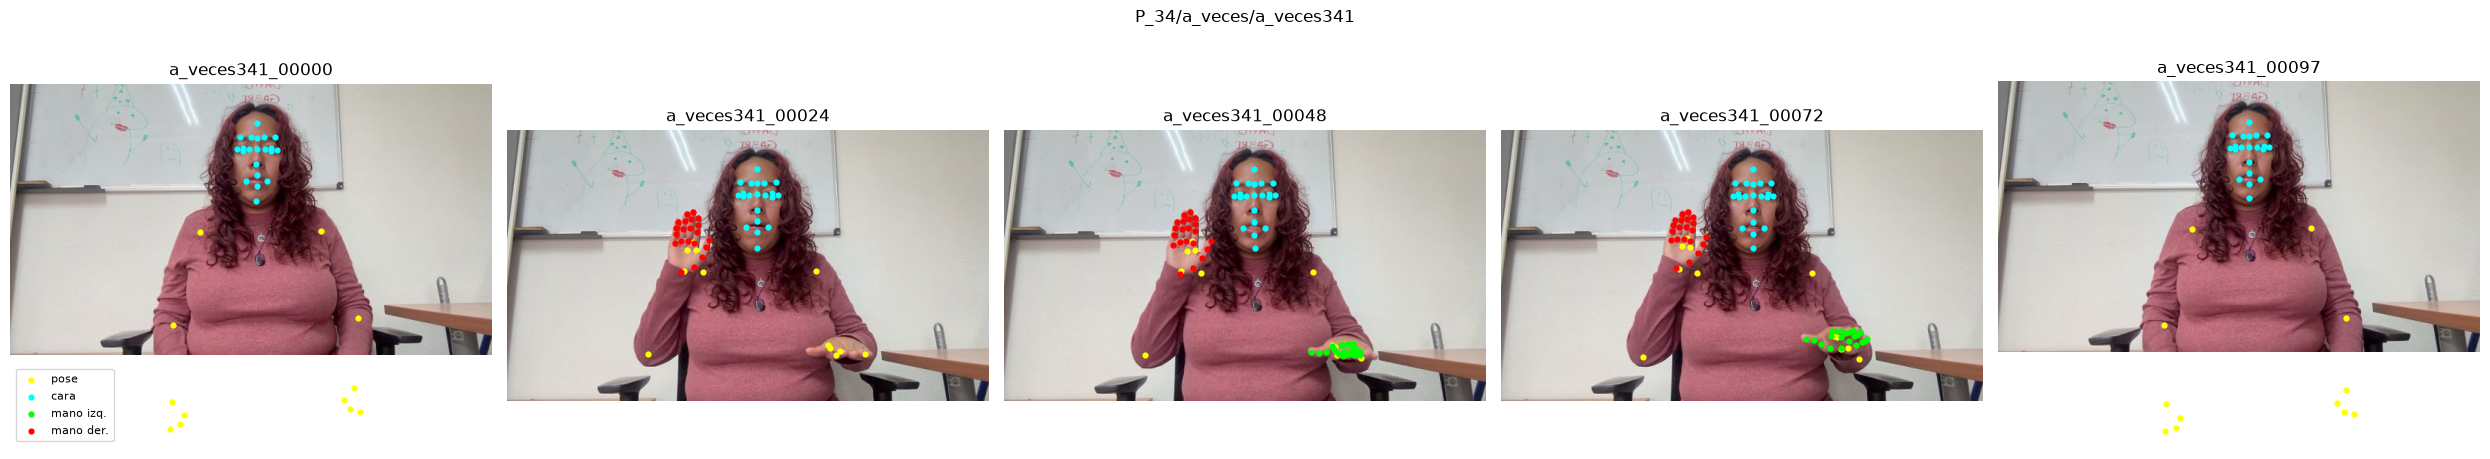

In [17]:
import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt

N_FRAMES = 5

CLIP = r"P_34\a_veces\a_veces341"

clip_dir = (DIR_KEYPOINTS / CLIP if CLIP
            else sorted({p.parent for p in DIR_KEYPOINTS.rglob("*.npy")})[0])
kp_paths = sorted(clip_dir.glob("*.npy"))
elegidos = [kp_paths[i] for i in np.linspace(0, len(kp_paths) - 1, N_FRAMES).astype(int)]

PARTES = [("pose", POSE, 4, "yellow"), ("cara", FACE, 3, "cyan"),
          ("mano izq.", LEFT_HAND, 3, "lime"), ("mano der.", RIGHT_HAND, 3, "red")]

fig, axes = plt.subplots(1, N_FRAMES, figsize=(5 * N_FRAMES, 5))
for ax, kp_path in zip(axes, elegidos):
    kp = np.load(kp_path)

    img_path = DIR_FRAMES / clip_dir.relative_to(DIR_KEYPOINTS) / f"{kp_path.stem}.jpg"
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax.imshow(img)

    for nombre, bloque, valores, color in PARTES:
        pts = kp[bloque].reshape(-1, valores)[:, :3]
        pts = pts[(pts != 0).any(axis=1)]            # quita los no detectados
        ax.scatter(pts[:, 0] * w, pts[:, 1] * h, s=12, c=color, label=nombre)

    ax.set_title(kp_path.stem)
    ax.axis("off")

axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(clip_dir.relative_to(DIR_KEYPOINTS).as_posix())
plt.tight_layout()
plt.show()

In [16]:
import os
print("cwd:", os.getcwd())
print("DIR_KEYPOINTS:", DIR_KEYPOINTS.resolve(), "| existe:", DIR_KEYPOINTS.exists())
print("CLIP:", CLIP)
print("clip_dir:", clip_dir.resolve(), "| existe:", clip_dir.exists())
print("contenido de clip_dir:", list(clip_dir.iterdir())[:10] if clip_dir.exists() else "no existe")
print("npy en total:", len(list(DIR_KEYPOINTS.rglob("*.npy"))))

cwd: c:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\time-series-to-slr
DIR_KEYPOINTS: C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\keypoints | existe: True
CLIP: C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\frames\P_34\a_veces\a_veces341
clip_dir: C:\Users\gvg\Desktop\mariangel-panama\time-series-to-transformer\0_frame_extraction\0_frame_extraction\frames\P_34\a_veces\a_veces341 | existe: True
contenido de clip_dir: [WindowsPath('C:/Users/gvg/Desktop/mariangel-panama/time-series-to-transformer/0_frame_extraction/0_frame_extraction/frames/P_34/a_veces/a_veces341/a_veces341_00000.jpg'), WindowsPath('C:/Users/gvg/Desktop/mariangel-panama/time-series-to-transformer/0_frame_extraction/0_frame_extraction/frames/P_34/a_veces/a_veces341/a_veces341_00001.jpg'), WindowsPath('C:/Users/gvg/Desktop/mariangel-panama/time-series-to-transformer/0_frame_extraction/0_fram

# 3. Split dataset

In [11]:
import json
import random
from collections import defaultdict

import pandas as pd

SEED = 42
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

# One sequence = one clip directory holding that clip's per-frame .npy files.
# Splitting whole clips (never individual frames) keeps near-identical frames
# from the same recording out of two different splits.
sequence_dirs = sorted({p.parent for p in DIR_KEYPOINTS.rglob("*.npy")})

clips_by_label = defaultdict(list)
for seq_dir in sequence_dirs:
    clips_by_label[seq_dir.parent.name].append(seq_dir)

rng = random.Random(SEED)
rows = []

# Stratified split, so every class keeps the same train/val/test proportions.
# With 10 clips per class the val/test shares are fractional (1.5 clips), so the
# spare clip goes to whichever split is furthest below its target share of
# everything seen so far. That keeps the dataset as a whole at 70/15/15 instead
# of letting the rounding always favour the same split.
assigned = {name: 0 for name in RATIOS}
n_seen = 0

for label in sorted(clips_by_label):
    clips = clips_by_label[label]
    rng.shuffle(clips)
    n_seen += len(clips)

    counts = {name: int(len(clips) * ratio) for name, ratio in RATIOS.items()}
    for _ in range(len(clips) - sum(counts.values())):
        behind = max(RATIOS, key=lambda s: RATIOS[s] * n_seen - (assigned[s] + counts[s]))
        counts[behind] += 1

    start = 0
    for name in RATIOS:
        for clip_dir in clips[start:start + counts[name]]:
            rows.append(
                {
                    "clip": clip_dir.relative_to(DIR_KEYPOINTS).as_posix(),
                    "label": label,
                    "n_frames": len(list(clip_dir.glob("*.npy"))),
                    "split": name,
                }
            )
        assigned[name] += counts[name]
        start += counts[name]

labels = sorted(clips_by_label)
splits_df = pd.DataFrame(rows).sort_values(["split", "label", "clip"]).reset_index(drop=True)
splits_df.to_csv(DIR_DATASET / "splits.csv", index=False)

# Provenance: everything needed to reproduce this exact split.
config = {
    "seed": SEED,
    "ratios": RATIOS,
    "unit": "clip",
    "stratified_by": "label",
    "signer_independent": False,
    "keypoints_dir": str(DIR_KEYPOINTS),
    "keypoint_dim": 237,
    "labels": labels,
    "n_clips": len(splits_df),
    "counts": {name: int(n) for name, n in splits_df["split"].value_counts().items()},
}
(DIR_DATASET / "split_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

for name in RATIOS:
    subset = splits_df[splits_df["split"] == name]
    per_class = subset["label"].value_counts().reindex(labels).to_dict()
    print(f"{name:5s}: {len(subset):3d} clips ({len(subset) / len(splits_df):.0%})  {per_class}")

print(f"\n{len(splits_df)} clips across {len(labels)} classes -> {DIR_DATASET / 'splits.csv'}")

train: 350 clips (70%)  {'a_veces': 35, 'buenos_dias': 35, 'como_se_dice': 35, 'cual_es_tu_nombre': 35, 'cuidado': 35, 'de_nada': 35, 'encantado_de_conocerte': 35, 'poco_a_poco': 35, 'por_favor': 35, 'repetir': 35}
val  :  75 clips (15%)  {'a_veces': 8, 'buenos_dias': 7, 'como_se_dice': 8, 'cual_es_tu_nombre': 7, 'cuidado': 8, 'de_nada': 7, 'encantado_de_conocerte': 8, 'poco_a_poco': 7, 'por_favor': 8, 'repetir': 7}
test :  75 clips (15%)  {'a_veces': 7, 'buenos_dias': 8, 'como_se_dice': 7, 'cual_es_tu_nombre': 8, 'cuidado': 7, 'de_nada': 8, 'encantado_de_conocerte': 7, 'poco_a_poco': 8, 'por_favor': 7, 'repetir': 8}

500 clips across 10 classes -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\split_dataset\splits.csv


# 3.b SPLIT LEAVE-ONE-SIGNER-OUT

In [12]:
import json
import random

import pandas as pd

# Leave-one-signer-out (LOSO) for a SMALL number of signers (works with 2 or more).
#
# Folder layout this expects:   DIR_KEYPOINTS / P_06 / a_veces / a_veces06_1 / <frame>.npy
#                                               ^person  ^sign     ^clip
#
# Each fold: one person is the TEST signer (never seen in training).
# The other people are TRAIN. A small share of their clips (stratified by sign)
# is held out as VALIDATION, used only for early stopping / choosing settings.
# Runs in your notebook: expects DIR_KEYPOINTS and DIR_DATASET_LOSO to be defined.

SEED = 42
VAL_FRACTION = 0.15         # share of the train clips (per sign) kept for validation
EXPECTED_SIGNERS = None     # set to the number of person folders once you've checked (e.g. 3)
CHECK_NAME_NUMBER = True    # warn if the number in a clip name differs from its person folder
OUT_DIR = DIR_DATASET_LOSO  # where splits_loso.csv and split_config_loso.json are written


def get_signer(seq_dir):
    """The person is the first folder of the path, e.g. 'P_06'."""
    return seq_dir.relative_to(DIR_KEYPOINTS).parts[0]


# One sequence = one clip directory holding that clip's per-frame .npy files.
sequence_dirs = sorted({p.parent for p in DIR_KEYPOINTS.rglob("*.npy")})

clips = pd.DataFrame(
    {
        "clip": [d.relative_to(DIR_KEYPOINTS).as_posix() for d in sequence_dirs],
        "label": [d.parent.name for d in sequence_dirs],
        "signer": [get_signer(d) for d in sequence_dirs],
        "n_frames": [len(list(d.glob("*.npy"))) for d in sequence_dirs],
    }
)

print("First clips and the signer read from each:")
for d in sequence_dirs[:8]:
    print("  ", d.relative_to(DIR_KEYPOINTS).as_posix(), "->", get_signer(d))

signers = sorted(clips["signer"].unique())
labels = sorted(clips["label"].unique())
assert len(signers) >= 2, f"LOSO needs at least 2 signers, found {len(signers)}: {signers}"
if EXPECTED_SIGNERS is not None:
    assert len(signers) == EXPECTED_SIGNERS, (
        f"Expected {EXPECTED_SIGNERS} signers but found {len(signers)}: {signers}."
    )
print("\nSigners found:", signers)

print("\nClips per signer and sign:")
print(pd.crosstab(clips["signer"], clips["label"]), "\n")

# Heuristic check: in names like 'a_veces06_1' the number (06) usually matches the person (P_06).
# If one clip is filed under the wrong person, that person leaks across splits.
if CHECK_NAME_NUMBER:
    in_name = pd.to_numeric(clips["clip"].str.extract(r"(\d{2})_\d+$")[0], errors="coerce")
    in_folder = pd.to_numeric(clips["signer"].str.extract(r"(\d+)")[0], errors="coerce")
    mismatch = clips[in_name.notna() & in_folder.notna() & (in_name != in_folder)]
    if len(mismatch):
        print(f"WARNING: {len(mismatch)} clips have a number in the name that differs from their person folder:")
        print(mismatch[["clip", "signer"]].head(20).to_string(), "\n")
    else:
        print("Name numbers match the person folders.\n")

rng = random.Random(SEED)
folds = []
frames = []

for i, test_signer in enumerate(signers):
    train_signers = [s for s in signers if s != test_signer]

    fold_df = clips.copy()
    fold_df["fold"] = i + 1
    fold_df["split"] = fold_df["signer"].map(
        lambda s: "test" if s == test_signer else "train"
    )

    # Carve validation clips out of the train clips, stratified by sign.
    for label in labels:
        idx = fold_df.index[
            (fold_df["split"] == "train") & (fold_df["label"] == label)
        ].tolist()
        rng.shuffle(idx)
        n_val = max(1, round(VAL_FRACTION * len(idx))) if len(idx) > 1 else 0
        fold_df.loc[idx[:n_val], "split"] = "val"

    # Sanity checks. A sign missing from train breaks training; missing from
    # test only means that person has no clips of that sign, so it is a warning.
    for split in ("train", "val", "test"):
        missing = set(labels) - set(fold_df.loc[fold_df["split"] == split, "label"])
        if missing:
            message = f"fold {i + 1}, {split}: missing signs {sorted(missing)}"
            if split == "test":
                print("WARNING:", message)
            else:
                raise AssertionError(message)

    frames.append(fold_df)
    folds.append({"fold": i + 1, "train_signers": train_signers, "test_signer": test_signer})

loso_df = (
    pd.concat(frames)
    .sort_values(["fold", "split", "label", "clip"])
    .reset_index(drop=True)
)
OUT_DIR.mkdir(parents=True, exist_ok=True)
loso_df.to_csv(OUT_DIR / "splits_loso.csv", index=False)

# Provenance: everything needed to reproduce this exact split.
config = {
    "scheme": "leave-one-signer-out",
    "unit": "clip",
    "test_signer_independent": True,
    "validation": "stratified clips taken from the train signers (not signer-independent)",
    "seed": SEED,
    "val_fraction": VAL_FRACTION,
    "keypoints_dir": str(DIR_KEYPOINTS),
    "keypoint_dim": 237,
    "signers": signers,
    "labels": labels,
    "folds": folds,
    "n_clips": len(clips),
}
(OUT_DIR / "split_config_loso.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

for f in folds:
    counts = loso_df[loso_df["fold"] == f["fold"]]["split"].value_counts()
    print(
        f"fold {f['fold']}: test={f['test_signer']}  train signers={f['train_signers']}  ->  "
        f"train {counts.get('train', 0)}, val {counts.get('val', 0)}, test {counts.get('test', 0)} clips"
    )

print(f"\n{len(signers)} signers, {len(clips)} clips -> {OUT_DIR / 'splits_loso.csv'}")

First clips and the signer read from each:
   P_06/a_veces/a_veces05_4 -> P_06
   P_06/a_veces/a_veces06_1 -> P_06
   P_06/a_veces/a_veces06_10 -> P_06
   P_06/a_veces/a_veces06_2 -> P_06
   P_06/a_veces/a_veces06_3 -> P_06
   P_06/a_veces/a_veces06_5 -> P_06
   P_06/a_veces/a_veces06_6 -> P_06
   P_06/a_veces/a_veces06_7 -> P_06

Signers found: ['P_06', 'P_09', 'P_10', 'P_33', 'P_34']

Clips per signer and sign:
label   a_veces  buenos_dias  como_se_dice  cual_es_tu_nombre  cuidado  \
signer                                                                   
P_06         10           10            10                 10       10   
P_09         10           10            10                 10       10   
P_10         10           10            10                 10       10   
P_33         10           10            10                 10       10   
P_34         10           10            10                 10       10   

label   de_nada  encantado_de_conocerte  poco_a_poco  por_favor 

# 4. Collapse .npy arrays into matrix

In [13]:
import numpy as np
DIR_SEQUENCES = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\sequences")
DIR_SEQUENCES.mkdir(parents=True, exist_ok=True)

splits_df = pd.read_csv(DIR_DATASET / "splits.csv")


# Collapse each clip's per-frame .npy files into a single (n_frames, 291) matrix,
# so training reads 100 files instead of 10,459. Lengths stay as recorded.
for row in splits_df.itertuples():
    frame_paths = sorted((DIR_KEYPOINTS / row.clip).glob("*.npy"))
    sequence = np.stack([np.load(p) for p in frame_paths]).astype(np.float32)
    assert len(sequence) == row.n_frames, f"{row.clip}: {len(sequence)} != {row.n_frames}"

    out_path = (DIR_SEQUENCES / row.clip).with_suffix(".npy")
    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(out_path, sequence)

print(f"{len(splits_df)} sequences -> {DIR_SEQUENCES}")
print(f"lengths: min {splits_df.n_frames.min()}, max {splits_df.n_frames.max()}, "
      f"mean {splits_df.n_frames.mean():.1f}")

500 sequences -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\sequences
lengths: min 40, max 196, mean 85.1


# 5. Normalize 

In [14]:
DIR_SEQUENCES_NORM = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\sequences_normalized")
DIR_SEQUENCES_NORM.mkdir(parents=True, exist_ok=True)

# POSE / FACE / LEFT_HAND / RIGHT_HAND, N_POSE and L_SHOULDER / R_SHOULDER all
# come from the keypoint extraction cell, so changing the landmark lists there
# is enough -- nothing here needs editing.


def normalize_sequence(sequence):
    """Make coordinates independent of where the signer stood.

    Every frame is recentred on the mid-shoulder point and divided by the
    shoulder width, so the same sign gives the same numbers whether the signer
    is near or far, left or right of frame. Landmarks MediaPipe did not detect
    are left at zero instead of being shifted to some arbitrary position.
    """
    out = sequence.copy()
    n = len(out)

    pose = out[:, POSE].reshape(n, N_POSE, 4)
    left, right = pose[:, L_SHOULDER, :2], pose[:, R_SHOULDER, :2]
    center = (left + right) / 2.0
    scale = np.linalg.norm(left - right, axis=1)
    scale[scale == 0] = 1.0  # no pose in this frame: leave it untouched

    for block, stride in [(POSE, 4), (FACE, 3), (LEFT_HAND, 3), (RIGHT_HAND, 3)]:
        points = out[:, block].reshape(n, -1, stride).copy()
        detected = (points[..., :3] != 0).any(-1)[..., None]

        shifted = points[..., :3].copy()
        shifted[..., 0] -= center[:, None, 0]
        shifted[..., 1] -= center[:, None, 1]
        shifted /= scale[:, None, None]

        points[..., :3] = np.where(detected, shifted, 0.0)
        out[:, block] = points.reshape(n, -1)

    return out


for row in splits_df.itertuples():
    sequence = np.load((DIR_SEQUENCES / row.clip).with_suffix(".npy"))
    out_path = (DIR_SEQUENCES_NORM / row.clip).with_suffix(".npy")
    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(out_path, normalize_sequence(sequence))

print(f"{len(splits_df)} sequences normalized -> {DIR_SEQUENCES_NORM}")

example_clip = splits_df["clip"].iloc[0]
check = np.load((DIR_SEQUENCES_NORM / example_clip).with_suffix(".npy"))
pose_xy = check[:, POSE].reshape(-1, N_POSE, 4)[..., :2]
print(f"example {example_clip}: shape {check.shape}, "
      f"pose x/y now {pose_xy.min():.2f}..{pose_xy.max():.2f} (shoulder widths from mid-shoulder)")

500 sequences normalized -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\sequences_normalized
example P_06/a_veces/a_veces06_1: shape (62, 237), pose x/y now -1.18..2.53 (shoulder widths from mid-shoulder)


# 6. Padding sequences

In [16]:
# MAX_LEN comes from the manifest, never hardcoded: record more participants,
# re-run, and the padding adapts to the new longest clip on its own.
MAX_LEN = int(splits_df["n_frames"].max())
# FEATURE_DIM comes from the keypoint extraction cell, so it follows the
# landmark lists automatically rather than being restated here.

config = json.loads((DIR_DATASET / "split_config.json").read_text(encoding="utf-8"))
labels = config["labels"]
label_to_index = {label: i for i, label in enumerate(labels)}

# Clips keep their real duration and are zero-padded at the end up to MAX_LEN.
# The padding is not data, so every split also stores the true lengths; the model
# rebuilds the mask from them (np.arange(MAX_LEN) < length) and never reads past
# the end of a clip.
for split in ("train", "val", "test"):
    subset = splits_df[splits_df["split"] == split].reset_index(drop=True)

    X = np.zeros((len(subset), MAX_LEN, FEATURE_DIM), dtype=np.float32)
    y = np.zeros(len(subset), dtype=np.int64)
    lengths = np.zeros(len(subset), dtype=np.int64)

    for i, row in enumerate(subset.itertuples()):
        sequence = np.load((DIR_SEQUENCES_NORM / row.clip).with_suffix(".npy"))
        X[i, :len(sequence)] = sequence
        y[i] = label_to_index[row.label]
        lengths[i] = len(sequence)

    np.savez_compressed(DIR_DATASET / f"{split}.npz", X=X, y=y, lengths=lengths)
    padding = 1 - lengths.sum() / (len(subset) * MAX_LEN)
    print(f"{split:5s}: X {X.shape}  y {y.shape}  {padding:.0%} of timesteps are padding")

config["max_len"] = MAX_LEN
config["feature_dim"] = FEATURE_DIM
config["spatial_normalization"] = "mid-shoulder centred, shoulder-width scaled"
(DIR_DATASET / "split_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"\nMAX_LEN = {MAX_LEN} (derived), written to split_config.json")

train: X (350, 196, 237)  y (350,)  57% of timesteps are padding
val  : X (75, 196, 237)  y (75,)  57% of timesteps are padding
test : X (75, 196, 237)  y (75,)  56% of timesteps are padding

MAX_LEN = 196 (derived), written to split_config.json


# 6.b PADDING LEAVE-ONE-SIGNER-OUT

In [15]:
import json
from pathlib import Path


DIR_SEQUENCES_NORM = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\sequences_normalized")
# MAX_LEN comes from the manifest, never hardcoded: record more participants,
# re-run, and the padding adapts to the new longest clip on its own.
splits_df = pd.read_csv(DIR_DATASET / "splits.csv")
loso_df = pd.read_csv(DIR_DATASET_LOSO / "splits_loso.csv")
MAX_LEN = int(max(splits_df["n_frames"].max(), loso_df["n_frames"].max()))
# FEATURE_DIM comes from the keypoint extraction cell, so it follows the
# landmark lists automatically rather than being restated here.

config = json.loads((DIR_DATASET_LOSO / "split_config_loso.json").read_text(encoding="utf-8"))
labels = config["labels"]
label_to_index = {label: i for i, label in enumerate(labels)}

# Clips keep their real duration and are zero-padded at the end up to MAX_LEN.
# The padding is not data, so every split also stores the true lengths; the model
# rebuilds the mask from them (np.arange(MAX_LEN) < length) and never reads past
# the end of a clip.

def build_npz (df,out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    for split in ("train", "val", "test"):
        subset = df[df["split"] == split].reset_index(drop=True)

        X = np.zeros((len(subset), MAX_LEN, FEATURE_DIM), dtype=np.float32)
        y = np.zeros(len(subset), dtype=np.int64)
        lengths = np.zeros(len(subset), dtype=np.int64)

        for i, row in enumerate(subset.itertuples()):
            sequence = np.load((DIR_SEQUENCES_NORM / row.clip).with_suffix(".npy"))
            X[i, :len(sequence)] = sequence
            y[i] = label_to_index[row.label]
            lengths[i] = len(sequence)

        np.savez_compressed(out_dir / f"{split}.npz", X=X, y=y, lengths=lengths)
        print(f"{out_dir.name}/{split}: X {X.shape}")

for fold, group in loso_df.groupby("fold"):           # LOSO: carpeta por fold
    build_npz(group, DIR_DATASET_LOSO / f"fold{fold}")

config["max_len"] = MAX_LEN
config["feature_dim"] = FEATURE_DIM
config["spatial_normalization"] = "mid-shoulder centred, shoulder-width scaled"
(DIR_DATASET_LOSO / "split_config_loso.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"\nMAX_LEN = {MAX_LEN}, FEATURE_DIM = {FEATURE_DIM}")

fold1/train: X (340, 196, 237)
fold1/val: X (60, 196, 237)
fold1/test: X (100, 196, 237)
fold2/train: X (340, 196, 237)
fold2/val: X (60, 196, 237)
fold2/test: X (100, 196, 237)
fold3/train: X (340, 196, 237)
fold3/val: X (60, 196, 237)
fold3/test: X (100, 196, 237)
fold4/train: X (340, 196, 237)
fold4/val: X (60, 196, 237)
fold4/test: X (100, 196, 237)
fold5/train: X (340, 196, 237)
fold5/val: X (60, 196, 237)
fold5/test: X (100, 196, 237)

MAX_LEN = 196, FEATURE_DIM = 237


# 7. Standarizing

In [17]:
# Per-feature standardization. The statistics come from the training clips only
# -- fitting them on val or test would leak information about the evaluation set.
train = np.load(DIR_DATASET / "train.npz")

train_mask = np.arange(MAX_LEN)[None, :] < train["lengths"][:, None]
real_frames = train["X"][train_mask]  # padding excluded from the statistics

mean = real_frames.mean(axis=0)
std = real_frames.std(axis=0)
std[std == 0] = 1.0  # constant features (e.g. landmarks never detected)

np.savez(DIR_DATASET / "feature_stats.npz", mean=mean, std=std)

for split in ("train", "val", "test"):
    data = np.load(DIR_DATASET / f"{split}.npz")
    X, lengths = data["X"], data["lengths"]

    mask = np.arange(MAX_LEN)[None, :] < lengths[:, None]
    X = np.where(mask[..., None], (X - mean) / std, 0.0).astype(np.float32)

    np.savez_compressed(
        DIR_DATASET / f"{split}_standardized.npz", X=X, y=data["y"], lengths=lengths
    )
    print(f"{split:5s}: mean {X[mask].mean():+.3f}  std {X[mask].std():.3f} (real frames only)")

print(f"\nstatistics from {len(real_frames)} training frames -> feature_stats.npz")

train: mean -0.001  std 1.000 (real frames only)
val  : mean +0.003  std 0.984 (real frames only)
test : mean -0.021  std 0.993 (real frames only)

statistics from 29753 training frames -> feature_stats.npz


# 7.b STANDARIZING LEAVE-ONE-SIGNER-OUT

In [43]:
def standardize_folder(folder):
    train = np.load(folder / "train.npz")
    X, lengths = train["X"], train["lengths"]
    max_len = X.shape[1]

    mask = np.arange(max_len)[None, :] < lengths[:, None]
    real = X[mask]                       # padding fuera
    detected = real != 0                 # 0 = keypoint no detectado, no es una medición
    n = np.maximum(detected.sum(0), 1)

    mean = (real * detected).sum(0) / n
    var = (((real - mean) ** 2) * detected).sum(0) / n
    std = np.sqrt(var)
    std[std < 1e-6] = 1.0                # features constantes / nunca detectadas

    np.savez(folder / "feature_stats.npz", mean=mean, std=std)

    for split in ("train", "val", "test"):
        f = folder / f"{split}.npz"
        if not f.exists():
            continue
        d = np.load(f)
        Xs, L = d["X"], d["lengths"]
        m = np.arange(max_len)[None, :] < L[:, None]
        keep = m[..., None] & (Xs != 0)  # frame real Y keypoint detectado
        Xs = np.where(keep, (Xs - mean) / std, 0.0).astype(np.float32)
        np.savez_compressed(folder / f"{split}_standardized.npz", X=Xs, y=d["y"], lengths=L)
        print(f"  {folder.name}/{split}: mean {Xs[keep].mean():+.3f}  std {Xs[keep].std():.3f}  "
              f"({1 - keep[m].mean():.0%} de los valores de frames reales no detectados)")

for k in (1, 2, 3,4,5):
    standardize_folder(DIR_DATASET_LOSO / f"fold{k}")

  fold1/train: mean -0.001  std 0.996  (12% de los valores de frames reales no detectados)
  fold1/val: mean +0.029  std 0.988  (11% de los valores de frames reales no detectados)
  fold1/test: mean +0.069  std 1.071  (9% de los valores de frames reales no detectados)
  fold2/train: mean -0.001  std 0.996  (9% de los valores de frames reales no detectados)
  fold2/val: mean +0.030  std 1.001  (9% de los valores de frames reales no detectados)
  fold2/test: mean -0.226  std 1.114  (18% de los valores de frames reales no detectados)
  fold3/train: mean -0.001  std 0.996  (12% de los valores de frames reales no detectados)
  fold3/val: mean +0.007  std 1.012  (12% de los valores de frames reales no detectados)
  fold3/test: mean +0.160  std 1.102  (7% de los valores de frames reales no detectados)
  fold4/train: mean -0.001  std 0.996  (12% de los valores de frames reales no detectados)
  fold4/val: mean +0.000  std 1.011  (12% de los valores de frames reales no detectados)
  fold4/test: 

# ---INVESTIGACION SALAMANCA---TRANSFORMERS

In [3]:
import torch # lo segundo será False con la versión CPU

In [4]:
from pathlib import Path
import json
import numpy as np

FOLD = 1                                                  # fold con el que vamos a mirar los datos en el paso 1

labels = json.loads((DIR_DATASET_LOSO / "split_config_loso.json").read_text(encoding="utf-8"))["labels"]
N_CLASSES = len(labels)
print(N_CLASSES, "señas:", labels)


def load(split, fold=FOLD):
    d = np.load(DIR_DATASET_LOSO / f"fold{fold}" / f"{split}_standardized.npz")
    return d["X"], d["y"], d["lengths"]

10 señas: ['a_veces', 'buenos_dias', 'como_se_dice', 'cual_es_tu_nombre', 'cuidado', 'de_nada', 'encantado_de_conocerte', 'poco_a_poco', 'por_favor', 'repetir']


In [5]:
for split in ("train", "val", "test"):
    X, y, L = load(split)
    print(f"{split:5s} X{X.shape}  clips={len(X):3d}  frames reales: min {L.min()} / media {L.mean():.0f} / max {L.max()}")

train X(340, 196, 237)  clips=340  frames reales: min 40 / media 91 / max 196
val   X(60, 196, 237)  clips= 60  frames reales: min 52 / media 89 / max 155
test  X(100, 196, 237)  clips=100  frames reales: min 41 / media 62 / max 87


padding en train: 53% de los timesteps son relleno (MAX_LEN=196)

duración media por seña (frames):
  a_veces          89.4   (n=34)
  buenos_dias      93.9   (n=34)
  como_se_dice     91.9   (n=34)
  cual_es_tu_nombre  107.3   (n=34)
  cuidado          75.6   (n=34)
  de_nada          75.7   (n=34)
  encantado_de_conocerte  115.2   (n=34)
  poco_a_poco      82.4   (n=34)
  por_favor       106.8   (n=34)
  repetir          73.9   (n=34)


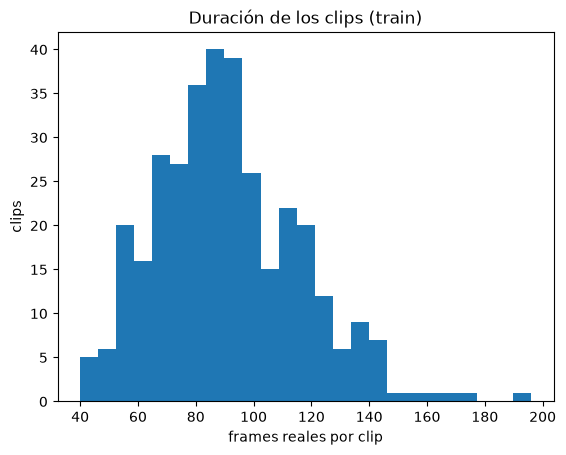

In [6]:
X, y, L = load("train")
MAX_LEN = X.shape[1]
print(f"padding en train: {1 - L.mean() / MAX_LEN:.0%} de los timesteps son relleno (MAX_LEN={MAX_LEN})\n")

print("duración media por seña (frames):")
for c, name in enumerate(labels):
    print(f"  {name:14s} {L[y == c].mean():6.1f}   (n={int((y == c).sum())})")

try:
    import matplotlib.pyplot as plt
    plt.hist(L, bins=25); plt.xlabel("frames reales por clip"); plt.ylabel("clips"); plt.title("Duración de los clips (train)")
    plt.show()
except ImportError:
    pass

In [39]:
mask = np.arange(MAX_LEN)[None, :] < L[:, None]            # True = frame real
undetected = (X == 0) & mask[..., None]                    # 0 = keypoint no detectado (en frames reales)

per_feature = undetected.sum((0, 1)) / mask.sum()          # fracción faltante de cada una de las 237 features
per_clip = undetected.sum((1, 2)) / (L * X.shape[2])       # fracción faltante de cada clip

print(f"no detectado, global: {undetected.sum() / (mask.sum() * X.shape[2]):.1%}")
print("por feature (min / mediana / max):", np.percentile(per_feature, [0, 50, 100]).round(2))
print("por clip    (min / mediana / max):", np.percentile(per_clip, [0, 50, 100]).round(2))
print("las 10 features con más faltantes (índice: fracción):",
      {int(i): float(per_feature[i].round(2)) for i in np.argsort(per_feature)[::-1][:10]})

no detectado, global: 13.1%
por feature (min / mediana / max): [0.  0.2 0.3]
por clip    (min / mediana / max): [0.   0.12 0.34]
las 10 features con más faltantes (índice: fracción): {236: 0.3, 235: 0.3, 234: 0.3, 233: 0.3, 232: 0.3, 231: 0.3, 230: 0.3, 229: 0.3, 228: 0.3, 227: 0.3}


In [44]:
def pool(X, L, mode):
    """Resume cada clip (T x 237) en un vector. Solo cuenta los frames reales."""
    mask = (np.arange(X.shape[1])[None, :] < L[:, None])[..., None]
    n = L[:, None].astype(np.float32)
    mean = (X * mask).sum(1) / n
    if mode == "mean":
        return mean
    var = (((X - mean[:, None, :]) ** 2) * mask).sum(1) / n
    return np.concatenate([mean, np.sqrt(var)], axis=1)


def fit_softmax(F, y, n_classes, l2=1e-2, lr=0.5, steps=400):
    """Regresión logística multiclase con descenso de gradiente (lo mismo que una capa Linear + softmax)."""
    mu, sd = F.mean(0), F.std(0) + 1e-6
    Z = (F - mu) / sd
    n = len(Z)
    W, b = np.zeros((Z.shape[1], n_classes)), np.zeros(n_classes)
    Y = np.eye(n_classes)[y]
    for _ in range(steps):
        logits = Z @ W + b
        logits -= logits.max(1, keepdims=True)
        P = np.exp(logits); P /= P.sum(1, keepdims=True)
        G = (P - Y) / n
        W -= lr * (Z.T @ G + l2 * W)
        b -= lr * G.sum(0)
    return mu, sd, W, b


def evaluate(model, F, y):
    mu, sd, W, b = model
    logits = ((F - mu) / sd) @ W + b
    logits -= logits.max(1, keepdims=True)
    P = np.exp(logits); P /= P.sum(1, keepdims=True)
    loss = -np.log(P[np.arange(len(y)), y] + 1e-12).mean()
    return loss, (P.argmax(1) == y).mean()


print(f"azar: accuracy {1 / N_CLASSES:.0%}, loss {np.log(N_CLASSES):.2f}\n")
print(f"{'fold':>4} {'entrada':>10} | {'train acc':>9} {'val acc':>8} {'test acc':>9} {'test loss':>10}")
results = {}
for fold in (1, 2, 3,4,5):
    data = {s: load(s, fold) for s in ("train", "val", "test")}
    for mode in ("mean", "mean+std"):
        F = {s: pool(X, L, mode) for s, (X, y, L) in data.items()}
        model = fit_softmax(F["train"], data["train"][1], N_CLASSES)
        tr = evaluate(model, F["train"], data["train"][1])
        va = evaluate(model, F["val"], data["val"][1])
        te = evaluate(model, F["test"], data["test"][1])
        results[(fold, mode)] = te[1]
        print(f"{fold:>4} {mode:>10} | {tr[1]:>9.0%} {va[1]:>8.0%} {te[1]:>9.0%} {te[0]:>10.2f}")

azar: accuracy 10%, loss 2.30

fold    entrada | train acc  val acc  test acc  test loss
   1       mean |      100%     100%       62%       1.87
   1   mean+std |      100%     100%       54%       1.47
   2       mean |      100%      97%       81%       0.94
   2   mean+std |      100%      97%       84%       0.79
   3       mean |      100%      97%       76%       0.59
   3   mean+std |      100%      97%       81%       0.52
   4       mean |      100%      98%       83%       0.51
   4   mean+std |      100%      98%       96%       0.15
   5       mean |      100%      98%       77%       0.61
   5   mean+std |      100%      98%       85%       0.42


## baseline en LOSO
azar: accuracy 10%, loss 2.30

|fold |   entrada | train acc | val acc | test acc | test loss |
|-----|-----------|-----------|---------|----------|-----------|
|   1 |      mean |      100% |     97% |      62% |      2.00 | 
|   1 |  mean+std |      100% |    97%  |     54%  |     1.67  |
|   2 |      mean |      100% |    100% |      59% |      2.02 | 
|   2 |  mean+std |      100% |    100% |      65% |      2.08 | 
|   3 |      mean |      100% |    100% |      76% |      0.56 | 
|   3 |  mean+std |      100% |     97% |      73% |      1.14 |

1. “El fold 3 fue el que mejor se comportó”: correcto. Sale mejor con las dos entradas (76 % y 73 %), y además tiene la menor loss (0.56 con “mean”). Aun así, con 100 clips de test el margen es de unos ±5 puntos, así que el fold 3 es claramente mejor que el fold 1 con “mean+std”, pero contra el fold 2 la diferencia es más débil.

2. “Hay overfitting”: correcto. Train está en 100 % y test entre 54 % y 76 %. Con ~170 clips y 237 a 474 features, un modelo lineal puede memorizar el train sin esfuerzo. Matiz: no todo ese hueco es overfitting. Una parte viene de que el test es otra persona, y eso se ve en que val (mismas personas que train) también da 97–100 %. La brecha entre val y test mide el cambio de persona, y la brecha entre train y val mide el overfitting puro, que aquí es casi nula.

3. “Le cuesta un poco reconocer a otra persona”: es cierto, pero “un poco” se queda corto. Caer de ~99 % en val a ~65 % en test son unos 35 puntos. Ese salto es lo más importante que muestra la tabla, y es lo que el paper tiene que reportar con LOSO.

4. “Los folds con test > 70 % pueden ser buen indicio de algo”: con cuidado. El 70 % es un umbral que has puesto tú, y no hay nada especial en él. Los 54 % también están muy por encima del azar (10 %). Un fold por encima del 70 % no significa mucho por sí solo. Lo que se reporta es el promedio entre folds y su dispersión, aquí unos 66 % con 54–76 % entre folds.

Qué sí indica que un fold salga alto en estos baselines: esos modelos ignoran el orden de los frames, así que 70 % o más quiere decir que la postura promedio ya separa bien las señas. Eso no es una señal de que el modelo vaya bien. Es una señal de que el listón está alto, y el GRU y los transformers tienen que superarlo.

#### split random

In [26]:
from pathlib import Path
import json
import numpy as np

SCHEME = "random"                                          # "random" o "loso"

FOLDS = ("random",) if SCHEME == "random" else (1, 2, 3)   # el aleatorio es un único "fold"

def fold_dir(fold):
    return DIR_DATASET if SCHEME == "random" else DIR_DATASET_LOSO / f"fold{fold}"

config_path = (DIR_DATASET / "split_config.json") if SCHEME == "random" else (DIR_DATASET_LOSO / "split_config_loso.json")
labels = json.loads(config_path.read_text(encoding="utf-8"))["labels"]
N_CLASSES = len(labels)
print(SCHEME, "| folds:", FOLDS, "|", N_CLASSES, "señas:", labels)

def load(split, fold=FOLDS[0]):
    d = np.load(fold_dir(fold) / f"{split}_standardized.npz")
    return d["X"], d["y"], d["lengths"]

random | folds: ('random',) | 10 señas: ['a_veces', 'buenos_dias', 'como_se_dice', 'cual_es_tu_nombre', 'cuidado', 'de_nada', 'encantado_de_conocerte', 'poco_a_poco', 'por_favor', 'repetir']


In [27]:
for split in ("train", "val", "test"):
    X, y, L = load(split)
    print(f"{split:5s} X{X.shape}  clips={len(X):3d}  frames reales: min {L.min()} / media {L.mean():.0f} / max {L.max()}")

train X(350, 196, 237)  clips=350  frames reales: min 40 / media 85 / max 172
val   X(75, 196, 237)  clips= 75  frames reales: min 41 / media 84 / max 149
test  X(75, 196, 237)  clips= 75  frames reales: min 44 / media 87 / max 196


padding en train: 57% de los timesteps son relleno (MAX_LEN=196)

duración media por seña (frames):
  a_veces          87.3   (n=35)
  buenos_dias      87.4   (n=35)
  como_se_dice     81.2   (n=35)
  cual_es_tu_nombre   95.4   (n=35)
  cuidado          72.4   (n=35)
  de_nada          68.8   (n=35)
  encantado_de_conocerte  106.3   (n=35)
  poco_a_poco      81.8   (n=35)
  por_favor        97.8   (n=35)
  repetir          71.8   (n=35)


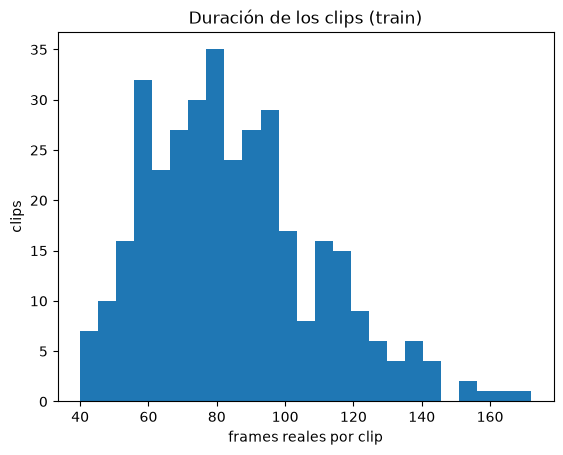

In [28]:
X, y, L = load("train")
MAX_LEN = X.shape[1]
print(f"padding en train: {1 - L.mean() / MAX_LEN:.0%} de los timesteps son relleno (MAX_LEN={MAX_LEN})\n")

print("duración media por seña (frames):")
for c, name in enumerate(labels):
    print(f"  {name:14s} {L[y == c].mean():6.1f}   (n={int((y == c).sum())})")

try:
    import matplotlib.pyplot as plt
    plt.hist(L, bins=25); plt.xlabel("frames reales por clip"); plt.ylabel("clips"); plt.title("Duración de los clips (train)")
    plt.show()
except ImportError:
    pass

In [29]:
mask = np.arange(MAX_LEN)[None, :] < L[:, None]            # True = frame real
undetected = (X == 0) & mask[..., None]                    # 0 = keypoint no detectado (en frames reales)

per_feature = undetected.sum((0, 1)) / mask.sum()          # fracción faltante de cada una de las 237 features
per_clip = undetected.sum((1, 2)) / (L * X.shape[2])       # fracción faltante de cada clip

print(f"no detectado, global: {undetected.sum() / (mask.sum() * X.shape[2]):.1%}")
print("por feature (min / mediana / max):", np.percentile(per_feature, [0, 50, 100]).round(2))
print("por clip    (min / mediana / max):", np.percentile(per_clip, [0, 50, 100]).round(2))
print("las 10 features con más faltantes (índice: fracción):",
      {int(i): float(per_feature[i].round(2)) for i in np.argsort(per_feature)[::-1][:10]})

no detectado, global: 0.0%
por feature (min / mediana / max): [0. 0. 0.]
por clip    (min / mediana / max): [0. 0. 0.]
las 10 features con más faltantes (índice: fracción): {7: 0.0, 82: 0.0, 234: 0.0, 235: 0.0, 236: 0.0, 231: 0.0, 230: 0.0, 229: 0.0, 228: 0.0, 227: 0.0}


In [30]:
def pool(X, L, mode):
    """Resume cada clip (T x 237) en un vector. Solo cuenta los frames reales."""
    mask = (np.arange(X.shape[1])[None, :] < L[:, None])[..., None]
    n = L[:, None].astype(np.float32)
    mean = (X * mask).sum(1) / n
    if mode == "mean":
        return mean
    var = (((X - mean[:, None, :]) ** 2) * mask).sum(1) / n
    return np.concatenate([mean, np.sqrt(var)], axis=1)


def fit_softmax(F, y, n_classes, l2=1e-2, lr=0.5, steps=400):
    """Regresión logística multiclase con descenso de gradiente (lo mismo que una capa Linear + softmax)."""
    mu, sd = F.mean(0), F.std(0) + 1e-6
    Z = (F - mu) / sd
    n = len(Z)
    W, b = np.zeros((Z.shape[1], n_classes)), np.zeros(n_classes)
    Y = np.eye(n_classes)[y]
    for _ in range(steps):
        logits = Z @ W + b
        logits -= logits.max(1, keepdims=True)
        P = np.exp(logits); P /= P.sum(1, keepdims=True)
        G = (P - Y) / n
        W -= lr * (Z.T @ G + l2 * W)
        b -= lr * G.sum(0)
    return mu, sd, W, b


def evaluate(model, F, y):
    mu, sd, W, b = model
    logits = ((F - mu) / sd) @ W + b
    logits -= logits.max(1, keepdims=True)
    P = np.exp(logits); P /= P.sum(1, keepdims=True)
    loss = -np.log(P[np.arange(len(y)), y] + 1e-12).mean()
    return loss, (P.argmax(1) == y).mean()


print(f"azar: accuracy {1 / N_CLASSES:.0%}, loss {np.log(N_CLASSES):.2f}\n")
print(f"{'fold':>4} {'entrada':>10} | {'train acc':>9} {'val acc':>8} {'test acc':>9} {'test loss':>10}")
results = {}
for fold in (1, 2, 3):
    data = {s: load(s, fold) for s in ("train", "val", "test")}
    for mode in ("mean", "mean+std"):
        F = {s: pool(X, L, mode) for s, (X, y, L) in data.items()}
        model = fit_softmax(F["train"], data["train"][1], N_CLASSES)
        tr = evaluate(model, F["train"], data["train"][1])
        va = evaluate(model, F["val"], data["val"][1])
        te = evaluate(model, F["test"], data["test"][1])
        results[(fold, mode)] = te[1]
        print(f"{fold:>4} {mode:>10} | {tr[1]:>9.0%} {va[1]:>8.0%} {te[1]:>9.0%} {te[0]:>10.2f}")

azar: accuracy 10%, loss 2.30

fold    entrada | train acc  val acc  test acc  test loss
   1       mean |      100%      97%       99%       0.11
   1   mean+std |      100%      97%       97%       0.08
   2       mean |      100%      97%       99%       0.11
   2   mean+std |      100%      97%       97%       0.08
   3       mean |      100%      97%       99%       0.11
   3   mean+std |      100%      97%       97%       0.08


## Baseline Split Random

azar: accuracy 10%, loss 2.30

|fold  |  entrada | train acc | val acc | test acc | test loss  |
|------|----------|-----------|---------|----------|------------|
|  1   |     mean |      100% |     98% |      96% |      0.14  |
|  1   | mean+std |      100% |     98% |     100% |      0.05  |
| 2    |   mean   |      100% |     98% |      96% |      0.14  |
| 2    | mean+std |      100% |     98% |     100% |      0.05  |
|  3   |    mean  |      100% |     98% |      96% |      0.14  |
|  3   | mean+std |      100% |     98% |     100% |      0.05  |

Overfitting es la brecha entre train y datos no vistos. Aquí train está en 100 % y test en 96–100 %, así que la brecha es casi nula. El modelo no memoriza más que antes. En LOSO el train también estaba en 100 %, y lo que cambiaba era el test (54–76 %). El modelo es el mismo y los datos de entrenamiento también. Solo cambia la pregunta que le haces al test.

|Esquema         |	Test	 | Qué mide                               |
|----------------|-----------|----------------------------------------|
|Split aleatorio |	96–100 % | Reconocer señas de personas que ya vio |
|LOSO	         | 54–76 %	 | Reconocer señas de una persona nueva   |

Con el split aleatorio, los clips de test vienen de las mismas personas que los de train. Cada persona repite 10 veces la misma seña con su propio estilo, así que un clip de test se parece mucho a sus hermanos del train. A eso se le llama fuga entre personas. La brecha de unos 30 a 40 puntos entre los dos esquemas es la medida de esa fuga con tus propios datos, y es el argumento para que LOSO sea el resultado principal del paper.

## ENTRENAMIENTO GRU+LOSO

In [4]:
from pathlib import Path
import json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence

BASELINE_TEST_ACC = 0.75                                  # el piso del paso 2 (mean, promedio de 3 folds)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
labels = json.loads((DIR_DATASET_LOSO / "split_config_loso.json").read_text(encoding="utf-8"))["labels"]
N_CLASSES = len(labels)
print("dispositivo:", DEVICE, "| señas:", N_CLASSES)


def load_fold(fold):
    out = {}
    for split in ("train", "val", "test"):
        d = np.load(DIR_DATASET_LOSO / f"fold{fold}" / f"{split}_standardized.npz")
        out[split] = (torch.tensor(d["X"]), torch.tensor(d["y"]), torch.tensor(d["lengths"]))
    return out

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

dispositivo: cuda | señas: 10


In [6]:
class GRUClassifier(nn.Module):
    def __init__(self, in_dim, hidden, n_classes, dropout=0.3, use_pack=True):
        super().__init__()
        self.use_pack = use_pack
        self.gru = nn.GRU(in_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, n_classes)

    def forward(self, x, lengths):
        if self.use_pack:
            packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
            _, h = self.gru(packed)           # se detiene en el último frame real de cada clip
        else:
            _, h = self.gru(x)                # lee también el relleno (solo para el experimento 3.4)
        return self.head(self.drop(h[-1]))    # (batch, n_classes)


m = GRUClassifier(237, 64, N_CLASSES)
print("parámetros:", sum(p.numel() for p in m.parameters()))

parámetros: 58826


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def batches(X, y, L, batch_size, shuffle):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), batch_size):
        j = idx[i:i + batch_size]
        lengths = L[j]
        T = int(lengths.max())                          # recorte al clip más largo de ESTE batch
        yield X[j, :T].to(DEVICE), y[j].to(DEVICE), lengths


@torch.no_grad()
def evaluate(model, data, batch_size=64):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb, lb in batches(*data, batch_size, False):
        logits = model(xb, lb)
        loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return loss_sum / n, correct / n

@torch.no_grad()
def predict(model, data, batch_size=64):
    model.eval()
    y_true, y_pred = [], []
    for xb, yb, lb in batches(*data, batch_size, False):
        y_pred += model(xb, lb).argmax(1).tolist()
        y_true += yb.tolist()
    return y_true, y_pred


def plot_confusion(model, data, labels=None, title=""):
    y_true, y_pred = predict(model, data)
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues")

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm


def train_one(fold, seed=0, hidden=64, use_pack=True, dropout=0.3, lr=1e-4, weight_decay=0.01,
              batch_size=16, max_epochs=300, patience=15, verbose=True):
    """Un entrenamiento = un modelo nuevo. Se queda con el mejor epoch según la loss de VALIDACIÓN."""
    set_seed(seed)
    data = load_fold(fold)
    model = GRUClassifier(data["train"][0].shape[2], hidden, N_CLASSES, dropout, use_pack).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history, best_val, best_epoch, best_state = [], float("inf"), 0, None
    for epoch in range(1, max_epochs + 1):
        model.train()
        loss_sum, n = 0.0, 0
        for xb, yb, lb in batches(*data["train"], batch_size, True):
            opt.zero_grad()
            loss = F.cross_entropy(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # evita gradientes enormes en secuencias largas
            opt.step()
            loss_sum += loss.item() * len(yb); n += len(yb)

        val_loss, val_acc = evaluate(model, data["val"])
        history.append(dict(epoch=epoch, train_loss=loss_sum / n, val_loss=val_loss, val_acc=val_acc))
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"  epoch {epoch:3d}  train loss {loss_sum / n:.3f}  val loss {val_loss:.3f}  val acc {val_acc:.0%}")
        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)                            # volver al mejor epoch
    tr_loss, tr_acc = evaluate(model, data["train"])
    va_loss, va_acc = evaluate(model, data["val"])
    te_loss, te_acc = evaluate(model, data["test"])
    return dict(fold=fold, seed=seed, hidden=hidden, use_pack=use_pack, best_epoch=best_epoch,
                epochs_run=epoch, train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc, test_loss=te_loss,
                n_params=sum(p.numel() for p in model.parameters()), history=history, model=model)

  epoch   1  train loss 2.317  val loss 2.283  val acc 17%
  epoch   5  train loss 1.636  val loss 1.730  val acc 48%
  epoch  10  train loss 0.882  val loss 0.987  val acc 82%
  epoch  15  train loss 0.357  val loss 0.468  val acc 93%
  epoch  20  train loss 0.157  val loss 0.278  val acc 95%
  epoch  25  train loss 0.081  val loss 0.200  val acc 95%
  epoch  30  train loss 0.056  val loss 0.171  val acc 95%
  epoch  35  train loss 0.042  val loss 0.146  val acc 95%
  epoch  40  train loss 0.033  val loss 0.129  val acc 97%
  epoch  45  train loss 0.022  val loss 0.109  val acc 97%
  epoch  50  train loss 0.017  val loss 0.129  val acc 95%
  epoch  55  train loss 0.015  val loss 0.097  val acc 97%
  epoch  60  train loss 0.013  val loss 0.139  val acc 95%
  epoch  65  train loss 0.012  val loss 0.109  val acc 95%
  epoch  70  train loss 0.009  val loss 0.111  val acc 95%
  epoch  75  train loss 0.009  val loss 0.125  val acc 95%
  epoch  80  train loss 0.007  val loss 0.074  val acc 9

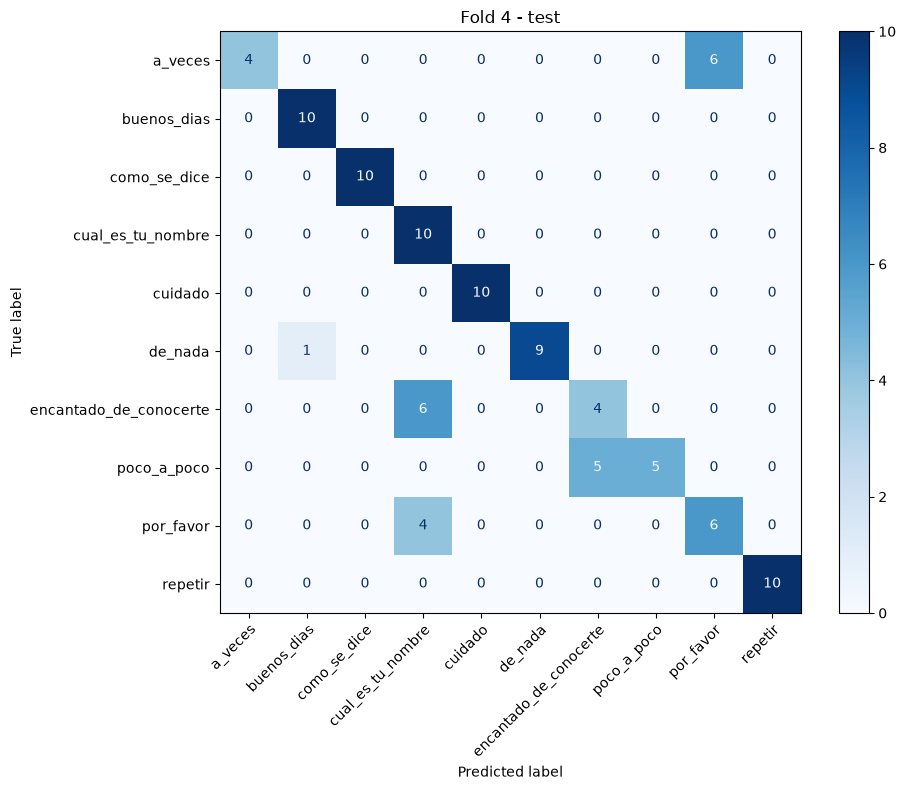

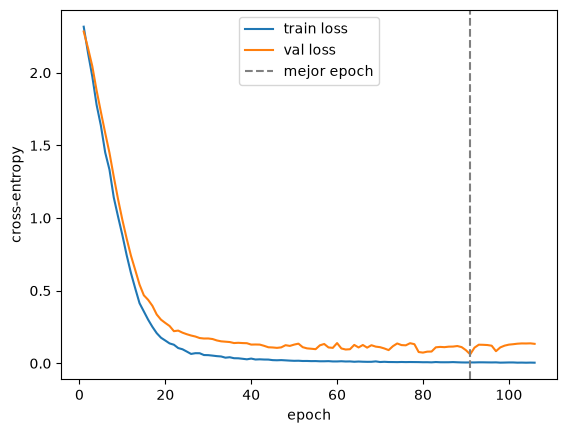

In [9]:
res = train_one(fold=4, seed=0)
print(f"\nmejor epoch: {res['best_epoch']} de {res['epochs_run']} | parámetros: {res['n_params']}")
print(f"train acc {res['train_acc']:.0%} | val acc {res['val_acc']:.0%} | test acc {res['test_acc']:.0%} | test loss {res['test_loss']:.2f}")
data = load_fold(4)
cm = plot_confusion(res["model"], data["test"], labels=labels, title="Fold 4 - test")

try:
    import matplotlib.pyplot as plt
    h = res["history"]
    plt.plot([r["epoch"] for r in h], [r["train_loss"] for r in h], label="train loss")
    plt.plot([r["epoch"] for r in h], [r["val_loss"] for r in h], label="val loss")
    plt.axvline(res["best_epoch"], ls="--", c="gray", label="mejor epoch")
    plt.xlabel("epoch"); plt.ylabel("cross-entropy"); plt.legend(); plt.show()
except ImportError:
    pass

In [10]:
rows = [train_one(fold=k, seed=0, verbose=False) for k in (1, 2, 3, 4, 5)]
print(f"{'fold':>4} | {'train':>6} {'val':>5} {'test':>5} | {'test loss':>9} | mejor epoch")
for r in rows:
    print(f"{r['fold']:>4} | {r['train_acc']:>6.0%} {r['val_acc']:>5.0%} {r['test_acc']:>5.0%} | {r['test_loss']:>9.2f} | {r['best_epoch']}")
mean_test = np.mean([r["test_acc"] for r in rows])
print(f"\ntest acc promedio: {mean_test:.0%}  (baseline sin orden: {BASELINE_TEST_ACC:.0%})  diferencia: {mean_test - BASELINE_TEST_ACC:+.0%}")

fold |  train   val  test | test loss | mejor epoch
   1 |   100%   98%   57% |      1.83 | 74
   2 |   100%   98%   74% |      0.97 | 42
   3 |   100%   97%   83% |      0.54 | 51
   4 |   100%   97%   78% |      0.72 | 91
   5 |   100%   97%   42% |      1.95 | 46

test acc promedio: 67%  (baseline sin orden: 75%)  diferencia: -8%


In [18]:
SEEDS = [0, 1, 2, 3, 4]
FOLDS = (1, 2, 3, 4, 5)

rows = [train_one(fold=k, seed=s, verbose=False) for s in SEEDS for k in FOLDS]
for r, (s, k) in zip(rows, [(s, k) for s in SEEDS for k in FOLDS]):
    r["seed"] = s  # por si train_one no la devuelve

print(f"{'seed':>4} | {'fold':>4} | {'train':>6} {'val':>5} {'test':>5} | {'test loss':>9} | mejor epoch")
for r in rows:
    print(f"{r['seed']:>4} | {r['fold']:>4} | {r['train_acc']:>6.0%} {r['val_acc']:>5.0%} "
          f"{r['test_acc']:>5.0%} | {r['test_loss']:>9.2f} | {r['best_epoch']}")
    if r["fold"] == FOLDS[-1]:
        print("-" * 58)

# Media entre folds para cada semilla
print(f"\n{'seed':>4} | {'test acc':>8} | {'test loss':>9}")
medias_seed = []
for s in SEEDS:
    rs = [r for r in rows if r["seed"] == s]
    acc = np.mean([r["test_acc"] for r in rs])
    loss = np.mean([r["test_loss"] for r in rs])
    medias_seed.append(acc)
    print(f"{s:>4} | {acc:>8.1%} | {loss:>9.3f}")

# Media de cada fold entre semillas (¿qué sujeto es difícil?)
print(f"\n{'fold':>4} | {'test acc media':>14} | {'std':>5}")
for k in FOLDS:
    accs = [r["test_acc"] for r in rows if r["fold"] == k]
    print(f"{k:>4} | {np.mean(accs):>14.1%} | {np.std(accs):>5.1%}")

mean_test = np.mean(medias_seed)
std_test = np.std(medias_seed)
print(f"\ntest acc promedio: {mean_test:.1%} ± {std_test:.1%} entre semillas  "
      f"(baseline sin orden: {BASELINE_TEST_ACC:.0%})  diferencia: {mean_test - BASELINE_TEST_ACC:+.1%}")

seed | fold |  train   val  test | test loss | mejor epoch
   0 |    1 |   100%   98%   56% |      2.22 | 94
   0 |    2 |   100%  100%   77% |      1.04 | 93
   0 |    3 |   100%   97%   80% |      0.56 | 57
   0 |    4 |   100%  100%   84% |      0.39 | 89
   0 |    5 |   100%   95%   43% |      1.82 | 38
----------------------------------------------------------
   1 |    1 |   100%   97%   59% |      1.95 | 72
   1 |    2 |   100%  100%   69% |      1.90 | 214
   1 |    3 |   100%   97%   83% |      0.59 | 58
   1 |    4 |   100%   97%   69% |      1.00 | 83
   1 |    5 |   100%   97%   59% |      1.44 | 67
----------------------------------------------------------
   2 |    1 |   100%  100%   46% |      2.69 | 147
   2 |    2 |   100%  100%   68% |      1.19 | 72
   2 |    3 |   100%   97%   76% |      0.65 | 71
   2 |    4 |   100%   97%   76% |      0.76 | 43
   2 |    5 |   100%   98%   35% |      1.91 | 49
----------------------------------------------------------
   3 |    1 

In [36]:
# IMPORTA EL MASK - QUE EL MODELO SEPA QUE ES PADDING Y NO KEYPOINT NO DETECTADO. SI NO, EL MODELO APRENDE A DECIR QUE ES CERO Y SE CONFUNDE.

print(f"{'fold':>4} | {'con máscara':>11} {'sin máscara':>11}  (test acc)")
accs = {True: [], False: []}
for k in (1, 2, 3):
    a = train_one(fold=k, seed=0, use_pack=True, verbose=False)["test_acc"]
    b = train_one(fold=k, seed=0, use_pack=False, verbose=False)["test_acc"]
    accs[True].append(a); accs[False].append(b)
    print(f"{k:>4} | {a:>11.0%} {b:>11.0%}")
print(f"prom | {np.mean(accs[True]):>11.0%} {np.mean(accs[False]):>11.0%}")

fold | con máscara sin máscara  (test acc)
   1 |         29%         34%
   2 |         43%         44%
   3 |         43%         27%
prom |         38%         35%


In [37]:
# Experimento 3.4: ¿cuántos parámetros necesita el modelo para aprender la tarea?
print(f"{'hidden':>6} {'params':>8} | {'train':>6} {'val':>5} {'test':>5}  (promedio de 3 folds, seed 0)")
for hidden in (32, 64, 128):
    rs = [train_one(fold=k, seed=0, hidden=hidden, verbose=False) for k in (1, 2, 3)]
    print(f"{hidden:>6} {rs[0]['n_params']:>8} | {np.mean([r['train_acc'] for r in rs]):>6.0%} "
          f"{np.mean([r['val_acc'] for r in rs]):>5.0%} {np.mean([r['test_acc'] for r in rs]):>5.0%}")

hidden   params |  train   val  test  (promedio de 3 folds, seed 0)
    32    26346 |   100%   97%   52%
    64    58826 |   100%   94%   38%
   128   142218 |   100%   97%   56%


## HIPERPARAMETROS RANDOM SEARCH

In [13]:
import json, random
import numpy as np
import pandas as pd

def sample_config(rng):
    return dict(
        lr=10 ** rng.uniform(-4, -2),                       # escala logarítmica
        weight_decay=rng.choice([0, 1e-5, 1e-4, 1e-3, 1e-2]),
        dropout=rng.choice([0.0, 0.1, 0.2, 0.3, 0.5]),
        hidden=rng.choice([16, 32, 64, 128]),
        batch_size=rng.choice([8, 16, 32]),
    )

def best_epoch_stats(r):
    """train_loss y val_loss en la época donde val_loss fue mínima."""
    h = r["history"]
    i = min(range(len(h)), key=lambda j: h[j]["val_loss"])
    return h[i]["train_loss"], h[i]["val_loss"], i + 1

def random_search(n_trials, folds, seeds, log_path="gru_search.jsonl", rng_seed=123):
    rng = random.Random(rng_seed)
    for t in range(n_trials):
        cfg = sample_config(rng)                              # hiperparámetros de este trial
        rs = [train_one(fold=k, seed=s, verbose=False, **cfg) for k in folds for s in seeds]
        stats = [best_epoch_stats(r) for r in rs]
        tr = [s[0] for s in stats]
        va = [s[1] for s in stats]
        ep = [s[2] for s in stats]
        row = dict(
            trial=t, **cfg,                                   # hiperparámetros
            train_loss=float(np.mean(tr)),
            val_loss=float(np.mean(va)),
            val_loss_std=float(np.std(va)),
            gap=float(np.mean(va) - np.mean(tr)),             # val_loss - train_loss
            best_epoch=float(np.mean(ep)),
            train_acc=float(np.mean([r["train_acc"] for r in rs])),
            val_acc=float(np.mean([r["val_acc"] for r in rs])),
        )
        with open(log_path, "a") as f:
            f.write(json.dumps(row) + "\n")
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

In [14]:
# 1) Prueba corta para medir el tiempo (borra el archivo después si quieres empezar limpio)
random_search(n_trials=2, folds=(1,2,3,4,5), seeds=(0, 1), log_path="gru_search_prueba.jsonl")

{'trial': 0, 'lr': 0.0001, 'weight_decay': 0, 'dropout': 0.3, 'hidden': 64, 'batch_size': 8, 'train_loss': 0.0066, 'val_loss': 0.0883, 'val_loss_std': 0.0793, 'gap': 0.0817, 'best_epoch': 145.3, 'train_acc': 1.0, 'val_acc': 0.9767}
{'trial': 1, 'lr': 0.0048, 'weight_decay': 0, 'dropout': 0.3, 'hidden': 64, 'batch_size': 16, 'train_loss': 0.0067, 'val_loss': 0.0984, 'val_loss_std': 0.0597, 'gap': 0.0917, 'best_epoch': 31.5, 'train_acc': 1.0, 'val_acc': 0.9733}


In [ ]:
# 2) Búsqueda completa
random_search(n_trials=20, folds=(1, 2, 3, 4, 5), seeds=(0, 1))

In [15]:
# 3) Leer y ordenar resultados
df = pd.read_json("gru_search.jsonl", lines=True)
cols = ["trial", "lr", "weight_decay", "dropout", "hidden", "batch_size",
        "train_loss", "val_loss", "val_loss_std", "gap", "best_epoch", "train_acc", "val_acc"]
df[cols].sort_values("val_loss").round(4)

FileNotFoundError: File gru_search.jsonl does not exist

### CONGELAR HYPERPARAMETERS

In [18]:
from pathlib import Path
from types import SimpleNamespace

C = SimpleNamespace(
    DATA_DIR=DIR_DATASET_LOSO,        # la variable que ya usas: contiene fold1/ ... fold5/
    RESULTS_DIR=Path("results"),
    N_CLASSES=10,
    IN_DIM=237,

    # Arquitectura (fija, propia de cada modelo)
    ARCH={
        "gru":   dict(hidden=64, dropout=0.3),
        "fact":  dict(attention="separated", d_model=64, heads=4, layers=2, mlp_ratio=2,
                      dropout=0.1, patch=4, order="st", use_det_flag=False),
        "joint": dict(attention="joint",     d_model=64, heads=4, layers=2, mlp_ratio=2,
                      dropout=0.1, patch=4, use_det_flag=False),
    },

    # Entrenamiento (fijo, igual para los tres)
    TRAIN=dict(optimizer="adamw", weight_decay=0.01, batch_size=16,
               warmup_frac=0.05, grad_clip=1.0, eval_every=25),

    # Piloto: misma lista de tasas para los tres modelos
    PILOT=dict(fold=1, seed=0, lrs=[3e-4, 1e-3, 3e-3], max_steps=3300),
)


In [19]:
import copy, json, math, random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score



# ----------------------------------------------------------------------------- utilidades
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_model(name):
    a = C.ARCH[name]
    if name == "gru":
        return GRUClassifier(C.IN_DIM, a["hidden"], C.N_CLASSES, dropout=a["dropout"])
    return SignTransformer(n_classes=C.N_CLASSES, **a)


def load_split(fold, split, idx=None):
    d = np.load(C.DATA_DIR / f"fold{fold}" / f"{split}_standardized.npz")
    X, y, L = d["X"], d["y"], d["lengths"]
    if idx is not None:                       # subconjunto de entrenamiento (E2)
        X, y, L = X[idx], y[idx], L[idx]
    return (torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long),
            torch.tensor(L, dtype=torch.long))


def batches(X, y, L, batch_size, shuffle, gen=None):
    n = len(y)
    order = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, batch_size):
        b = order[i:i + batch_size]
        Lb = L[b]
        T = int(Lb.max())                     # padding dinámico: recorta al clip más largo del lote
        yield X[b, :T], y[b], Lb


@torch.no_grad()
def evaluate(model, data, device, batch_size=64):
    model.eval()
    X, y, L = data
    logits = []
    for xb, _, lb in batches(X, y, L, batch_size, shuffle=False):
        logits.append(model(xb.to(device), lb.to(device)).float().cpu())
    logits = torch.cat(logits)
    pred = logits.argmax(1)
    return dict(
        loss=F.cross_entropy(logits, y).item(),
        acc=(pred == y).float().mean().item(),
        f1_macro=f1_score(y.numpy(), pred.numpy(), average="macro"),
        pred=pred.tolist(), true=y.tolist(),
    )


def lr_lambda(max_steps, warmup_frac):
    warm = max(1, int(warmup_frac * max_steps))
    def f(step):
        if step < warm:
            return (step + 1) / warm
        p = (step - warm) / max(1, max_steps - warm)
        return 0.5 * (1 + math.cos(math.pi * p))
    return f


# ----------------------------------------------------------------------------- sanity checks
def sanity_check(model_name, fold=1, device="cpu", steps=300):
    """Paso 0.4: pérdida inicial ~ ln(10) y capacidad de memorizar un mini-batch."""
    set_seed(0)
    model = build_model(model_name).to(device)
    X, y, L = load_split(fold, "train")
    xb, yb, lb = next(batches(X, y, L, C.TRAIN["batch_size"], shuffle=True,
                              gen=torch.Generator().manual_seed(0)))
    xb, yb, lb = xb.to(device), yb.to(device), lb.to(device)

    model.eval()
    with torch.no_grad():
        init = F.cross_entropy(model(xb, lb), yb).item()

    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
    for _ in range(steps):
        opt.zero_grad()
        loss = F.cross_entropy(model(xb, lb), yb)
        loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        final = F.cross_entropy(model(xb, lb), yb).item()
        acc = (model(xb, lb).argmax(1) == yb).float().mean().item()

    # padding: añadir frames de relleno no debe cambiar la salida
    with torch.no_grad():
        pad = torch.zeros(xb.shape[0], 8, xb.shape[2], device=device)
        diff = (model(xb, lb) - model(torch.cat([xb, pad], 1), lb)).abs().max().item()

    ok = abs(init - math.log(C.N_CLASSES)) < 0.5 and acc == 1.0 and diff < 1e-4
    print(f"[sanity] {model_name:5s} params={count_params(model):>8,}  "
          f"pérdida inicial={init:.2f} (esperado ~{math.log(C.N_CLASSES):.2f})  "
          f"tras memorizar 1 lote={final:.3f} acc={acc:.0%}  "
          f"efecto del relleno={diff:.1e}  -> {'OK' if ok else 'REVISAR'}")
    return ok


# ----------------------------------------------------------------------------- una corrida
def run(model_name, fold, seed, lr, max_steps, k="all", train_idx=None,
        eval_test=False, out_path=None, device=None):
    """Entrena un modelo y devuelve (y guarda) sus resultados.

    - El checkpoint final es el de menor pérdida de validación.
    - El test solo se evalúa si eval_test=True (nunca en el piloto).
    - Si out_path ya existe, no se vuelve a entrenar (reanudable).
    """
    if out_path is not None and out_path.exists():
        print(f"  ya existe, se salta: {out_path.name}")
        return json.loads(out_path.read_text())

    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)

    train = load_split(fold, "train", train_idx)
    val = load_split(fold, "val")

    model = build_model(model_name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=C.TRAIN["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(max_steps, C.TRAIN["warmup_frac"]))

    history, best = [], dict(val_loss=float("inf"))
    best_state, step, t0 = None, 0, time.time()
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()

    while step < max_steps:
        model.train()
        for xb, yb, lb in batches(*train, C.TRAIN["batch_size"], shuffle=True, gen=gen):
            xb, yb, lb = xb.to(device), yb.to(device), lb.to(device)
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), C.TRAIN["grad_clip"])
            opt.step(); sched.step(); step += 1

            if step % C.TRAIN["eval_every"] == 0 or step == max_steps:
                v = evaluate(model, val, device)
                history.append(dict(step=step, train_loss=loss.item(),
                                    val_loss=v["loss"], val_acc=v["acc"]))
                if v["loss"] < best["val_loss"]:
                    best = dict(step=step, val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1_macro"])
                    best_state = copy.deepcopy(model.state_dict())
                model.train()
            if step >= max_steps:
                break

    if device == "cuda":
        torch.cuda.synchronize()
    res = dict(
        model=model_name, fold=fold, seed=seed, lr=lr, k=k, max_steps=max_steps,
        params=count_params(model), arch=C.ARCH[model_name], train_cfg=C.TRAIN,
        train_time_s=time.time() - t0,
        peak_mem_gb=(torch.cuda.max_memory_allocated() / 1e9) if device == "cuda" else None,
        best=best, history=history,
    )

    if eval_test:                             # solo en E1/E2, con el checkpoint elegido por validación
        model.load_state_dict(best_state)
        t = evaluate(model, load_split(fold, "test"), device)
        res["test"] = dict(loss=t["loss"], acc=t["acc"], f1_macro=t["f1_macro"])
        res["test_pred"], res["test_true"] = t["pred"], t["true"]

    if out_path is not None:
        out_path.parent.mkdir(parents=True, exist_ok=True)
        out_path.write_text(json.dumps(res, indent=1))
    return res

In [24]:
for m in ["gru", "fact", "joint"]:
    sanity_check(m, fold=C.PILOT["fold"])

[sanity] gru   params=  58,826  pérdida inicial=2.51 (esperado ~2.30)  tras memorizar 1 lote=0.007 acc=100%  efecto del relleno=0.0e+00  -> OK
[sanity] fact  params= 110,282  pérdida inicial=2.46 (esperado ~2.30)  tras memorizar 1 lote=0.002 acc=100%  efecto del relleno=0.0e+00  -> OK
[sanity] joint params=  76,746  pérdida inicial=2.26 (esperado ~2.30)  tras memorizar 1 lote=0.002 acc=100%  efecto del relleno=0.0e+00  -> OK


In [26]:
MODELS = ["joint"] #luego poner "joint"

OUT = C.RESULTS_DIR / "pilot"
P = C.PILOT
for m in MODELS:
    for lr in P["lrs"]:
        print(f"\n== {m}  lr={lr:g}")
        r = run(m, fold=P["fold"], seed=P["seed"], lr=lr, max_steps=P["max_steps"],
                eval_test=False, out_path=OUT / f"{m}_lr{lr:g}.json")
        b = r["best"]
        print(f"  mejor val_loss={b['val_loss']:.3f}  val_acc={b['val_acc']:.1%}  "
              f"en el paso {b['step']}  ({r['train_time_s'] / 60:.1f} min)")


== joint  lr=0.0003
  mejor val_loss=0.016  val_acc=100.0%  en el paso 1975  (5.9 min)

== joint  lr=0.001
  mejor val_loss=0.004  val_acc=100.0%  en el paso 2775  (5.9 min)

== joint  lr=0.003
  mejor val_loss=0.000  val_acc=100.0%  en el paso 3250  (5.8 min)


modelo  lr       val_loss  val_acc  paso_mejor  min
gru     0.0003   0.029     100.0%     3175      0.7  <- elegida
gru     0.001    0.049     98.3%     1050      0.7
gru     0.003    0.044     98.3%      425      0.7
fact    0.0003   0.016     100.0%     2300      1.3
fact    0.001    0.008     100.0%     2550      1.3
fact    0.003    0.000     100.0%     3250      1.3  <- elegida
joint   0.0003   0.016     100.0%     1975      5.9
joint   0.001    0.004     100.0%     2775      5.9
joint   0.003    0.000     100.0%     3250      5.8  <- elegida


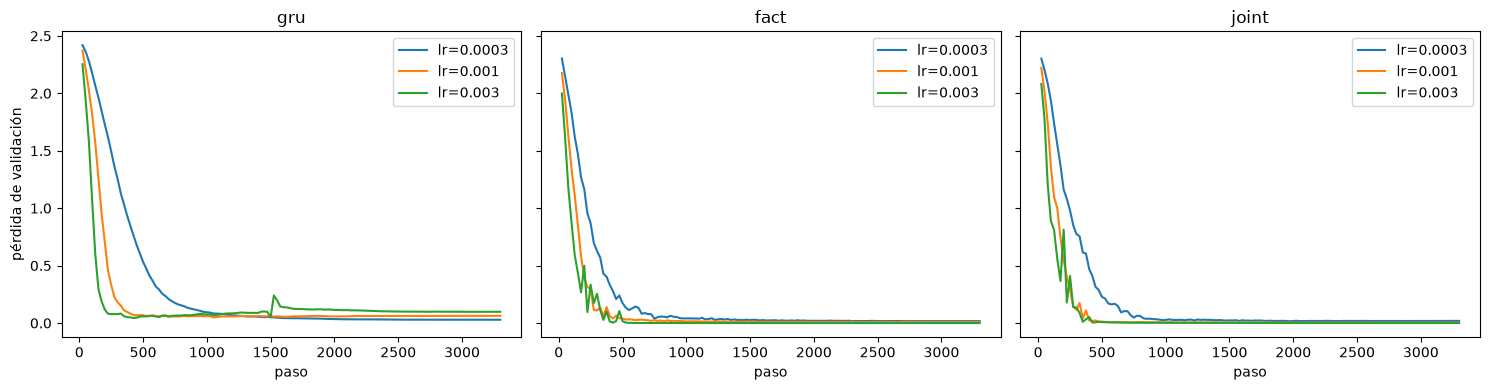

In [27]:
import matplotlib.pyplot as plt

rows = [json.loads(f.read_text()) for f in sorted(OUT.glob("*.json"))]
print("modelo  lr       val_loss  val_acc  paso_mejor  min")
for m in ["gru", "fact", "joint"]:
    rs = [r for r in rows if r["model"] == m]
    if not rs:
        continue
    win = min(rs, key=lambda r: r["best"]["val_loss"])
    for r in sorted(rs, key=lambda r: r["lr"]):
        b = r["best"]
        mark = "  <- elegida" if r is win else ""
        print(f"{m:6s}  {r['lr']:<7g}  {b['val_loss']:.3f}     {b['val_acc']:.1%}    "
              f"{b['step']:>5d}     {r['train_time_s'] / 60:4.1f}{mark}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, m in zip(axes, ["gru", "fact", "joint"]):
    for r in sorted([r for r in rows if r["model"] == m], key=lambda r: r["lr"]):
        h = r["history"]
        ax.plot([e["step"] for e in h], [e["val_loss"] for e in h], label=f"lr={r['lr']:g}")
    ax.set_title(m); ax.set_xlabel("paso")
    if ax.lines:
        ax.legend()
axes[0].set_ylabel("pérdida de validación")
plt.tight_layout(); plt.savefig(OUT / "pilot_curves.png", dpi=120); plt.show()

### PROBAR CON PYTORCH CUDA

In [11]:
import time
t0 = time.time()
r = train_one(fold=1, seed=0, verbose=False)
dt = time.time() - t0
print(f"{dt:.0f} s, {len(r['history'])} épocas, {dt/len(r['history']):.2f} s/época, DEVICE={DEVICE}")

35 s, 89 épocas, 0.40 s/época, DEVICE=cuda


### Generar loss graph and matrices de confusion con varios seeds y folds y configuraciones

Fold 1 | config: {'hidden': 64, 'dropout': 0.3, 'lr': 0.0048, 'weight_decay': 0, 'batch_size': 16}
      mejor_epoca  epocas_corridas  train_loss  val_loss     gap  val_acc
seed                                                                     
0               9               24      0.0103    0.1936  0.1834   0.9500
1              15               30      0.0043    0.0392  0.0349   0.9833
2              32               47      0.0011    0.0042  0.0031   1.0000

Resumen (media ± std entre seeds):
  val_loss: 0.0790 ± 0.0823
  val_acc: 0.9778 ± 0.0208
  mejor_epoca: 18.6667 ± 9.7411

[diagnóstico, no usar para elegir] test_acc por seed: [0.41, 0.45, 0.42] | media 0.427


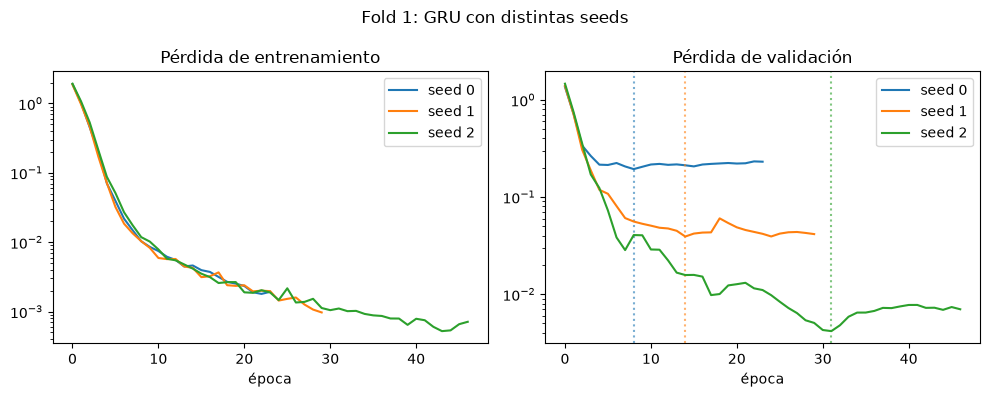

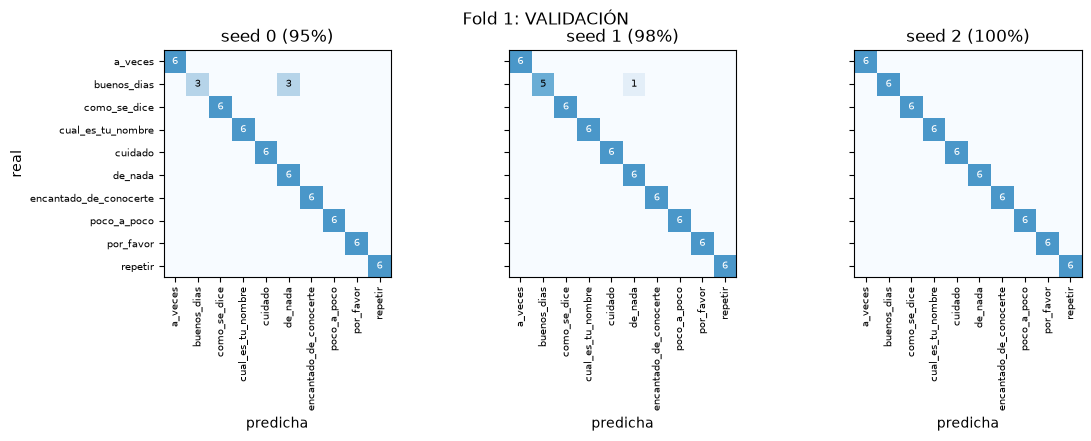

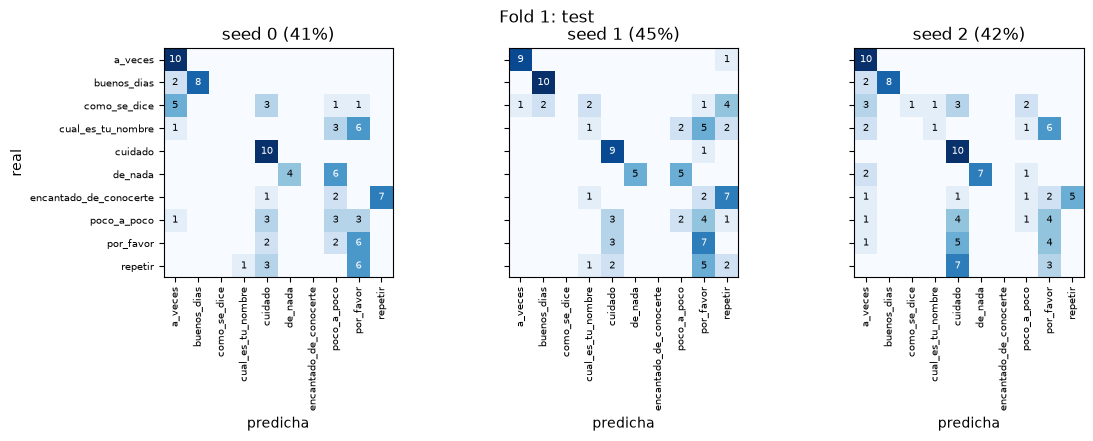

In [40]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

FOLD = 1
SEEDS = (0, 1, 2)
CFG = dict(hidden=64, dropout=0.3, lr=4.8e-3, weight_decay=0, batch_size=16)

@torch.no_grad()
def predict_split(model, fold, split="test", bs=32):
    model.eval()
    X, y, L = load_fold(fold)[split]
    preds = []
    for i in range(0, len(X), bs):
        preds.append(model(X[i:i + bs].to(DEVICE), L[i:i + bs]).argmax(1).cpu())
    return y.numpy(), torch.cat(preds).numpy()

def confusion(y_true, y_pred, n=10):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def evaluate_config(fold, seeds, cfg):
    rows, runs = [], {}
    for s in seeds:
        r = train_one(fold=fold, seed=s, verbose=False, **cfg)
        h = r["history"]
        i = int(np.argmin([e["val_loss"] for e in h]))            # mejor época según validación
        tl, vl = h[i]["train_loss"], h[i]["val_loss"]
        cm_val = confusion(*predict_split(r["model"], fold, "val"))
        cm_test = confusion(*predict_split(r["model"], fold, "test"))
        rows.append(dict(seed=s, mejor_epoca=i + 1, epocas_corridas=len(h),
                         train_loss=tl, val_loss=vl, gap=vl - tl,
                         val_acc=np.trace(cm_val) / cm_val.sum(),
                         test_acc=np.trace(cm_test) / cm_test.sum()))
        runs[s] = dict(history=h, cm_val=cm_val, cm_test=cm_test)
    return pd.DataFrame(rows).set_index("seed"), runs

df, runs = evaluate_config(FOLD, SEEDS, CFG)

# --- Métricas para ELEGIR la configuración (solo validación) ---
sel = ["mejor_epoca", "epocas_corridas", "train_loss", "val_loss", "gap", "val_acc"]
print(f"Fold {FOLD} | config: {CFG}")
print(df[sel].round(4))
print("\nResumen (media ± std entre seeds):")
for c in ["val_loss", "val_acc", "mejor_epoca"]:
    print(f"  {c}: {df[c].mean():.4f} ± {df[c].std(ddof=0):.4f}")

# --- Solo DIAGNÓSTICO: no usar para decidir ---
print("\n[diagnóstico, no usar para elegir] test_acc por seed:", df["test_acc"].round(3).tolist(),
      f"| media {df['test_acc'].mean():.3f}")

# Curvas de loss
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for s, run in runs.items():
    tr = [e["train_loss"] for e in run["history"]]
    va = [e["val_loss"] for e in run["history"]]
    line, = ax[0].plot(tr, label=f"seed {s}")
    ax[1].plot(va, color=line.get_color(), label=f"seed {s}")
    ax[1].axvline(int(np.argmin(va)), color=line.get_color(), ls=":", alpha=0.6)
ax[0].set_title("Pérdida de entrenamiento"); ax[1].set_title("Pérdida de validación")
for a in ax:
    a.set_xlabel("época"); a.set_yscale("log"); a.legend()
fig.suptitle(f"Fold {FOLD}: GRU con distintas seeds")
fig.tight_layout(); fig.savefig(f"loss_fold{FOLD}_seeds.png", dpi=200)

# Matrices: validación (para decidir) y test (para reportar), con tu plot_folds
plot_folds({s: r["cm_val"] for s, r in runs.items()}, {s: f"seed {s}" for s in runs}, labels,
           f"Fold {FOLD}: VALIDACIÓN", f"cm_val_fold{FOLD}_seeds.png")
plot_folds({s: r["cm_test"] for s, r in runs.items()}, {s: f"seed {s}" for s in runs}, labels,
           f"Fold {FOLD}: test", f"cm_test_fold{FOLD}_seeds.png")

In [45]:
import numpy as np, pandas as pd, torch
import torch.nn.functional as F

@torch.no_grad()
def eval_split(model, fold, split, bs=32):
    """Devuelve (loss, accuracy) del modelo sobre un conjunto. Loss = entropía cruzada media por clip."""
    model.eval()
    X, y, L = load_fold(fold)[split]
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        logits = model(X[i:i + bs].to(DEVICE), L[i:i + bs])
        yb = y[i:i + bs].to(DEVICE)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)

def full_report(fold, seeds, cfg):
    rows = []
    for s in seeds:
        r = train_one(fold=fold, seed=s, verbose=False, **cfg)
        row = dict(seed=s, epocas=len(r["history"]))
        for split in ("train", "val", "test"):
            loss, acc = eval_split(r["model"], fold, split)
            row[f"{split}_loss"], row[f"{split}_acc"] = loss, acc
        rows.append(row)
    return pd.DataFrame(rows).set_index("seed")

FOLD = 5
SEEDS = (0, 1, 2)
CFG = dict(hidden=32, dropout=0.3, lr=1e-3, weight_decay=1e-4, batch_size=16)

df = full_report(FOLD, SEEDS, CFG)
cols = ["train_loss", "val_loss", "test_loss", "train_acc", "val_acc", "test_acc"]
print(f"Fold {FOLD} | {CFG}")
print(df[["epocas"] + cols].round(4))
print("\nMedia ± std entre seeds:")
for c in cols:
    print(f"  {c:>10}: {df[c].mean():.4f} ± {df[c].std(ddof=0):.4f}")

Fold 5 | {'hidden': 32, 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 16}
      epocas  train_loss  val_loss  test_loss  train_acc  val_acc  test_acc
seed                                                                       
0         61      0.0096    0.1072     1.9552        1.0   0.9667      0.42
1         67      0.0067    0.1254     1.5188        1.0   0.9667      0.60
2         58      0.0113    0.0583     2.0503        1.0   0.9833      0.40

Media ± std entre seeds:
  train_loss: 0.0092 ± 0.0019
    val_loss: 0.0970 ± 0.0283
   test_loss: 1.8414 ± 0.2314
   train_acc: 1.0000 ± 0.0000
     val_acc: 0.9722 ± 0.0079
    test_acc: 0.4733 ± 0.0899


# TRANSFORMERS

#### Paso 1. Patchifying

In [32]:
import torch
import torch.nn.functional as F

# ---------------------------------------------------------------------------
# 1. DESCRIBIR CÓMO ESTÁ ARMADO EL VECTOR DE 237 NÚMEROS DE UN FRAME
# ---------------------------------------------------------------------------
# Estos tres números salen de tus constantes de extracción
# (len(POSE_LANDMARK_IDS), len(FACE_LANDMARK_IDS) y 21 por mano).
N_POSE, N_FACE, N_HAND = 12, 21, 21

# Cada grupo: (nombre, cuántos keypoints, cuántos valores tiene cada uno).
# El ORDEN es el del vector original: pose | cara | mano izquierda | mano derecha.
LAYOUT = [
    ("pose",       N_POSE, 4),      # x, y, z, visibilidad
    ("face",       N_FACE, 3),      # x, y, z
    ("left_hand",  N_HAND, 3),      # x, y, z
    ("right_hand", N_HAND, 3),      # x, y, z
]
N_KP = sum(n for _, n, _ in LAYOUT)             # 12 + 21 + 21 + 21 = 75 keypoints
FEAT_DIM = sum(n * c for _, n, c in LAYOUT)     # 48 + 63 + 63 + 63 = 237 números por frame
KP_CH = 4                                       # canales por keypoint tras unificar (x, y, z, vis)
assert (N_KP, FEAT_DIM) == (75, 237), (N_KP, FEAT_DIM)   # si falla, revisa las constantes de arriba


# ---------------------------------------------------------------------------
# 2. DE UN VECTOR PLANO DE 237 A UNA TABLA DE 75 KEYPOINTS
# ---------------------------------------------------------------------------
def to_keypoints(x):
    """(B, T, 237) -> (B, T, 75, 4).

    B = clips, T = frames, 75 = keypoints, 4 = x, y, z y visibilidad.
    No cambia ningún valor ni su orden: solo corta el vector en grupos.
    """
    B, T, _ = x.shape
    grupos, inicio = [], 0
    for _, n, c in LAYOUT:
        # Toma las n*c columnas de este grupo y las parte en n keypoints de c valores.
        g = x[..., inicio:inicio + n * c].reshape(B, T, n, c)
        if c < KP_CH:
            # La cara y las manos no tienen visibilidad: se rellena con un 0 para que
            # todos los keypoints tengan 4 canales y se puedan apilar en una sola tabla.
            g = F.pad(g, (0, KP_CH - c))
        grupos.append(g)
        inicio += n * c
    return torch.cat(grupos, dim=2)      # apila todos los keypoints en el eje 2 -> 75


# ---------------------------------------------------------------------------
# 3. AGRUPAR FRAMES CONSECUTIVOS EN PATCHES
# ---------------------------------------------------------------------------
def patchify(kp, patch):
    """(B, T, N, C) -> (B, Tp, N, patch*C).

    Un token pasa a ser un keypoint durante `patch` frames seguidos:
    los valores de esos frames quedan uno detrás de otro en el mismo vector.
    No se descarta ni se interpola nada.
    """
    B, T, N, C = kp.shape
    falta = (-T) % patch                 # cuántos frames faltan para llegar a un múltiplo de `patch`
    if falta:
        # Rellena con ceros al final de la dimensión del tiempo.
        # (F.pad recibe los pares de relleno empezando por la última dimensión: C, N, T.)
        kp = F.pad(kp, (0, 0, 0, 0, 0, falta))
    Tp = kp.shape[1] // patch            # número de patches
    kp = kp.reshape(B, Tp, patch, N, C)  # separa el tiempo en (patches, frames dentro del patch)
    kp = kp.permute(0, 1, 3, 2, 4)       # -> (B, Tp, N, patch, C): junta los frames de cada keypoint
    return kp.reshape(B, Tp, N, patch * C)


# ---------------------------------------------------------------------------
# 4. COMPROBACIONES (valores concretos, no solo formas)
# ---------------------------------------------------------------------------
d = load_fold(4)
def check_step1(X, patch=4):
    kp = to_keypoints(X)
    assert torch.equal(kp[:, :, 0,  :4], X[:, :, 0:4])
    assert torch.equal(kp[:, :, 12, :3], X[:, :, 48:51])
    assert torch.equal(kp[:, :, 33, :3], X[:, :, 111:114])
    assert torch.equal(kp[:, :, 54, :3], X[:, :, 174:177])
    assert (kp[:, :, 12:, 3] == 0).all()
    tok = patchify(kp, patch)
    assert torch.equal(tok[:, 2, 5].reshape(-1, patch, 4), kp[:, 2 * patch:3 * patch, 5])
    print("paso 1 OK", kp.shape, tok.shape)

for split in ("train", "val", "test"):
    X, y, L = d[split]
    check_step1(X)

paso 1 OK torch.Size([340, 196, 75, 4]) torch.Size([340, 49, 75, 16])
paso 1 OK torch.Size([60, 196, 75, 4]) torch.Size([60, 49, 75, 16])
paso 1 OK torch.Size([100, 196, 75, 4]) torch.Size([100, 49, 75, 16])


#### Paso 2. PatchEmbedding

In [33]:
import math
import torch.nn as nn

class PatchEmbed(nn.Module):
    def __init__(self, d_model=64, patch=4, max_len=196, use_det_flag=False, dropout=0.1):
        super().__init__()
        self.patch = patch
        self.use_det_flag = use_det_flag
        self.max_patches = math.ceil(max_len / patch)            # 196 / 4 = 49 posiciones temporales posibles
        in_ch = KP_CH + (1 if use_det_flag else 0)               # 4 canales + 1 de "detectado" = 5
        self.proj = nn.Linear(patch * in_ch, d_model)            # 4 frames x 5 canales = 20 números -> 64
        self.kp_emb = nn.Parameter(torch.zeros(N_KP, d_model))   # un vector aprendido por cada keypoint (75)
        self.t_emb = nn.Parameter(torch.zeros(self.max_patches, d_model))  # uno por posición de patch (49)
        nn.init.trunc_normal_(self.kp_emb, std=0.02)             # arrancan casi en cero y se ajustan al entrenar
        nn.init.trunc_normal_(self.t_emb, std=0.02)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, lengths):
        # x: (B, T, 237) con relleno; lengths: (B,) frames reales de cada clip (mismo dispositivo que x)
        T = int(lengths.max())
        x = x[:, :T]                                             # padding dinámico: recorta al clip más largo del lote
        kp = to_keypoints(x)                                     # (B, T, 75, 4)
        if self.use_det_flag:
            # keypoint no detectado = x, y, z en cero exacto. El flag deja que el modelo lo distinga de una posición real.
            #10_nov -> se decide no utilizar las flags para que el la comparison con el baseline sea más justa. El modelo debe aprender a ignorar los keypoints no detectados.
            det = (kp[..., :3] != 0).any(dim=-1, keepdim=True).to(kp.dtype)
            kp = torch.cat([kp, det], dim=-1)                    # (B, T, 75, 5)
        tok = patchify(kp, self.patch)                           # (B, Tp, 75, patch*5)
        Tp = tok.shape[1]
        assert Tp <= self.max_patches, f"clip de {T} frames: excede max_len ({self.max_patches * self.patch})"
        # proyección + etiqueta de "qué keypoint es" + etiqueta de "en qué momento ocurre"
        h = self.proj(tok) + self.kp_emb[None, None] + self.t_emb[None, :Tp, None]
        # un patch es válido si contiene al menos un frame real (los demás son relleno)
        valid = (torch.arange(Tp, device=x.device)[None] * self.patch) < lengths[:, None]
        return self.drop(h), valid

In [12]:
emb = PatchEmbed(d_model=64, patch=4, max_len=196).to(DEVICE).eval()
X, y, L = load_fold(4)["train"]
x, l = X[:4].to(DEVICE), L[:4].to(DEVICE)

h, valid = emb(x, l)
print(h.shape, valid.shape)        # (4, Tp, 75, 64) y (4, Tp), con Tp = ceil(l.max() / 4)

# 1) patches válidos de cada clip = ceil(longitud / 4)
assert (valid.sum(1).cpu() == torch.ceil(L[:4].float() / 4).long()).all()

# 2) con entradas idénticas (ceros), los tokens deben diferir solo por las etiquetas
z = torch.zeros(1, 8, 237, device=DEVICE)
hz, _ = emb(z, torch.tensor([8], device=DEVICE))
assert not torch.allclose(hz[0, 0, 0], hz[0, 0, 1])    # keypoint 0 distinto de keypoint 1
assert not torch.allclose(hz[0, 0, 0], hz[0, 1, 0])    # patch 0 distinto de patch 1

# 3) conteo de parámetros: 20*64 + 64 (proyección) + 75*64 (keypoints) + 49*64 (posiciones) = 9280
print(sum(p.numel() for p in emb.parameters()))
print("paso 2 OK")

torch.Size([4, 19, 75, 64]) torch.Size([4, 19])
9024
paso 2 OK


#### Paso 3. Atención con máscara

In [34]:
import torch.nn.functional as F

class MHA(nn.Module):
    def __init__(self, d_model=64, heads=4, dropout=0.1):
        super().__init__()
        assert d_model % heads == 0                   # 64 / 4 = 16 números por head
        self.h = heads
        self.qkv = nn.Linear(d_model, 3 * d_model)    # calcula Q, K y V de una sola vez
        self.out = nn.Linear(d_model, d_model)        # mezcla los heads al final
        self.p = dropout

    def forward(self, x, key_valid=None):
        # x: (B', L, d). key_valid: (B', L) booleano, True = token real, False = relleno
        B, L, D = x.shape
        # (B, L, 3, heads, D/heads) -> (3, B, heads, L, D/heads): separa Q, K, V y reparte los heads
        q, k, v = self.qkv(x).reshape(B, L, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        mask = None if key_valid is None else key_valid[:, None, None, :]   # True = se puede atender
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           dropout_p=self.p if self.training else 0.0)
        return self.out(y.transpose(1, 2).reshape(B, L, D))   # junta los heads y proyecta

In [15]:
torch.manual_seed(0)
mha = MHA(d_model=64, heads=4, dropout=0.0).to(DEVICE).eval()
x = torch.randn(2, 10, 64, device=DEVICE)
valid = torch.ones(2, 10, dtype=torch.bool, device=DEVICE)
valid[1, 6:] = False                              # el segundo clip solo tiene 6 tokens reales

y1 = mha(x, valid)

# 1) cambiar los tokens de relleno no altera la salida de los tokens reales
x2 = x.clone()
x2[1, 6:] = torch.randn(4, 64, device=DEVICE) * 10
assert torch.allclose(y1[1, :6], mha(x2, valid)[1, :6], atol=1e-5)

# 2) coincide con la fórmula escrita a mano
def manual(m, x, valid):
    B, L, D = x.shape; h = m.h
    q, k, v = m.qkv(x).reshape(B, L, 3, h, D // h).permute(2, 0, 3, 1, 4)
    s = q @ k.transpose(-1, -2) / (D // h) ** 0.5
    s = s.masked_fill(~valid[:, None, None, :], float("-inf"))
    return m.out((s.softmax(-1) @ v).transpose(1, 2).reshape(B, L, D))

assert torch.allclose(y1[:, :6], manual(mha, x, valid)[:, :6], atol=1e-5)
print("paso 3 OK")

paso 3 OK


#### Paso 4. Capas transformer

In [35]:
class MLP(nn.Module):
    def __init__(self, d_model=64, ratio=2, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, ratio * d_model)    # 64 -> 128
        self.fc2 = nn.Linear(ratio * d_model, d_model)    # 128 -> 64
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.drop(F.gelu(self.fc1(x))))   # procesa cada token por separado


class SeparatedLayer(nn.Module):
    def __init__(self, d_model=64, heads=4, mlp_ratio=2, dropout=0.1, order="st"):
        super().__init__()
        assert order in ("st", "ts")                       # st = espacial primero, ts = temporal primero
        self.order = order
        self.ln_s, self.ln_t, self.ln_m = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn_s = MHA(d_model, heads, dropout)         # atención espacial
        self.attn_t = MHA(d_model, heads, dropout)         # atención temporal
        self.mlp = MLP(d_model, mlp_ratio, dropout)
        self.drop = nn.Dropout(dropout)

    def spatial(self, x):                                  # x: (B, Tp, N, D)
        B, Tp, N, D = x.shape
        z = self.ln_s(x).reshape(B * Tp, N, D)             # cada patch = una secuencia de N keypoints
        z = self.attn_s(z).reshape(B, Tp, N, D)
        return x + self.drop(z)

    def temporal(self, x, valid):
        B, Tp, N, D = x.shape
        z = self.ln_t(x).permute(0, 2, 1, 3).reshape(B * N, Tp, D)   # cada keypoint = una secuencia de Tp patches
        kv = valid[:, None, :].expand(B, N, Tp).reshape(B * N, Tp)    # ignora los patches de relleno
        z = self.attn_t(z, kv).reshape(B, N, Tp, D).permute(0, 2, 1, 3)
        return x + self.drop(z)

    def forward(self, x, valid):
        if self.order == "st":
            x = self.temporal(self.spatial(x), valid)
        else:
            x = self.spatial(self.temporal(x, valid))
        return x + self.drop(self.mlp(self.ln_m(x)))


class JointLayer(nn.Module):
    def __init__(self, d_model=64, heads=4, mlp_ratio=2, dropout=0.1):
        super().__init__()
        self.ln_a, self.ln_m = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MHA(d_model, heads, dropout)
        self.mlp = MLP(d_model, mlp_ratio, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, valid):
        B, Tp, N, D = x.shape
        z = self.ln_a(x).reshape(B, Tp * N, D)             # todos los tokens en una sola secuencia
        kv = valid[:, :, None].expand(B, Tp, N).reshape(B, Tp * N)   # misma máscara, repetida por keypoint
        z = self.attn(z, kv).reshape(B, Tp, N, D)
        x = x + self.drop(z)
        return x + self.drop(self.mlp(self.ln_m(x)))

In [17]:
torch.manual_seed(0)
x = torch.randn(2, 6, 75, 64, device=DEVICE)
valid = torch.ones(2, 6, dtype=torch.bool, device=DEVICE)
valid[1, 4:] = False                                       # el segundo clip tiene 4 patches reales

esperado = {"separada": 50240, "conjunta": 33472}
for name, layer in (("separada", SeparatedLayer()), ("conjunta", JointLayer())):
    layer = layer.to(DEVICE).eval()
    y = layer(x, valid)
    assert y.shape == x.shape                              # la forma no cambia

    x2 = x.clone()
    x2[1, 4:] = torch.randn(2, 75, 64, device=DEVICE) * 10   # cambia solo el relleno
    assert torch.allclose(y[1, :4], layer(x2, valid)[1, :4], atol=1e-4), name

    n = sum(p.numel() for p in layer.parameters())
    assert n == esperado[name], (name, n)
    print(name, "OK", n, "parámetros")
print("paso 4 OK")

separada OK 50240 parámetros
conjunta OK 33472 parámetros
paso 4 OK


#### Paso 5. Modelo integrado, separado y conjunto

In [30]:
class SignTransformer(nn.Module):
    """El modelo completo. Solo cambia `attention`; todo lo demás es idéntico entre los dos."""

    def __init__(self, attention="separated", n_classes=10, d_model=64, heads=4, layers=2,
                 mlp_ratio=2, dropout=0.1, patch=4, max_len=196, order="st", use_det_flag=False):
        super().__init__()
        assert attention in ("separated", "joint")

        # 1) Entrada común: (B, T, 237) -> tokens (B, Tp, 75, d_model) + máscara de patches válidos
        self.embed = PatchEmbed(d_model, patch, max_len, use_det_flag, dropout)

        # 2) Pila de bloques: ESTA es la única diferencia entre los dos modelos
        if attention == "separated":
            self.layers = nn.ModuleList(
                [SeparatedLayer(d_model, heads, mlp_ratio, dropout, order) for _ in range(layers)])
        else:
            self.layers = nn.ModuleList(
                [JointLayer(d_model, heads, mlp_ratio, dropout) for _ in range(layers)])

        # 3) Salida: normalización final + clasificador lineal (64 -> 10 señas)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x, lengths):
        # x: (B, T, 237) estandarizado y con relleno; lengths: (B,) largo real de cada clip
        h, valid = self.embed(x, lengths)          # h: (B, Tp, N, D); valid: (B, Tp)
        for layer in self.layers:                  # pasa por los bloques en orden
            h = layer(h, valid)
        h = self.norm(h)

        # Promedio sobre todos los tokens REALES (patches válidos × 75 keypoints) -> 1 vector por clip
        w = valid[:, :, None, None].to(h.dtype)                       # (B, Tp, 1, 1)
        denom = valid.sum(dim=1, keepdim=True).to(h.dtype) * h.shape[2]   # (B, 1): patches válidos × N
        pooled = (h * w).sum(dim=(1, 2)) / denom                      # (B, D)
        return self.head(pooled)                                      # (B, n_classes)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [19]:
# MAX_LEN se lee de los datos, no se escribe a mano
X, y, L = load_fold(4)["train"]
MAX_LEN = int(L.max())
print("MAX_LEN =", MAX_LEN)

xb = torch.as_tensor(X[:16], dtype=torch.float32)     # 16 clips reales
yb = torch.as_tensor(y[:16], dtype=torch.long)
Lb = torch.as_tensor(L[:16], dtype=torch.long)

for att in ("separated", "joint"):
    m = SignTransformer(att, max_len=MAX_LEN).eval()  # eval: sin dropout, para que sea determinista
    with torch.no_grad():
        logits = m(xb, Lb)
        loss = F.cross_entropy(logits, yb)
    assert logits.shape == (16, 10), logits.shape
    print(f"{att:10s} logits {tuple(logits.shape)}  params {count_params(m):,}  loss inicial {loss:.3f}")

print("paso 5 OK")

MAX_LEN = 172
separated  logits (16, 10)  params 109,898  loss inicial 2.348
joint      logits (16, 10)  params 76,362  loss inicial 2.883
paso 5 OK


In [20]:
MAX_LEN = max(
    int(load_fold(k)[split][2].max())
    for k in range(1, 6)
    for split in ("train", "val", "test")
)
print("MAX_LEN global =", MAX_LEN)

MAX_LEN global = 196


In [62]:
for att in ("separated", "joint"):
    ls = []
    for s in range(10):
        set_seed(s)
        m = SignTransformer(att, max_len=MAX_LEN).eval()
        with torch.no_grad():
            ls.append(F.cross_entropy(m(xb, Lb), yb).item())
    print(att, f"media {sum(ls)/len(ls):.2f}  min {min(ls):.2f}  max {max(ls):.2f}")

separated media 2.46  min 1.95  max 3.95
joint media 2.51  min 1.69  max 3.35


#### Paso 6. Bucle de entrenamiento

In [17]:
import copy

def to_device(split):
    """Pasa un split completo a la GPU. Son ~340 clips (~60 MB): caben enteros, así no hace falta DataLoader."""
    X, y, L = split
    return (torch.as_tensor(X, dtype=torch.float32, device=DEVICE),
            torch.as_tensor(y, dtype=torch.long,    device=DEVICE),
            torch.as_tensor(L, dtype=torch.long,    device=DEVICE))   # lengths en el MISMO dispositivo que x


@torch.no_grad()
def evaluate_tf(model, split, bs=32):
    """Pérdida y accuracy sobre un split ya en GPU. Sin dropout, sin gradientes."""
    model.eval()
    X, y, L = split
    tot_loss, correct = 0.0, 0
    for i in range(0, len(y), bs):
        logits = model(X[i:i+bs], L[i:i+bs])
        tot_loss += F.cross_entropy(logits, y[i:i+bs], reduction="sum").item()   # suma, para promediar bien al final
        correct  += (logits.argmax(1) == y[i:i+bs]).sum().item()
    return tot_loss / len(y), correct / len(y)


def train_transformer(model, data, lr=1e-3, weight_decay=1e-2, batch_size=16,
                      max_epochs=300, patience=20, warmup_steps=100, clip=1.0):
    """
    data: dict {"train": (X,y,L), "val": ..., "test": ...}  (lo que devuelve tu load_fold)
    Entrena con AdamW, parada temprana por val_loss, y devuelve el modelo con los pesos de la MEJOR época.
    La semilla se fija FUERA (set_seed(s) antes de crear el modelo): así cambia la inicialización y el orden de los lotes.
    """
    model.to(DEVICE)
    tr, va = to_device(data["train"]), to_device(data["val"])
    Xtr, ytr, Ltr = tr
    n = len(ytr)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    # calentamiento: el lr sube linealmente de ~0 a `lr` en `warmup_steps` pasos y luego se queda fijo
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: min(1.0, (step + 1) / warmup_steps))

    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_state, best_epoch, bad = float("inf"), None, -1, 0

    for epoch in range(max_epochs):                       # REPEAT: épocas
        model.train()
        perm = torch.randperm(n, device=DEVICE)           # orden nuevo en cada época
        run = 0.0
        for i in range(0, n, batch_size):                 # REPEAT: lotes
            idx = perm[i:i+batch_size]
            logits = model(Xtr[idx], Ltr[idx])            # GUESS
            loss = F.cross_entropy(logits, ytr[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()                               # gradientes
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)   # evita pasos enormes
            opt.step()                                    # CHANGE
            sched.step()
            run += loss.item() * len(idx)

        val_loss, val_acc = evaluate_tf(model, va)
        hist["train_loss"].append(run / n)                # con dropout activo: no es comparable 1:1 con val_loss
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_loss < best_val - 1e-4:                    # mejoró: guarda una copia de los pesos
            best_val, best_epoch, bad = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:                           # `patience` épocas sin mejorar: para
                break

    #model.load_state_dict(best_state)                     # vuelve a la mejor época, no a la última
    return model, hist, best_epoch

In [70]:
set_seed(0)
X, y, L = load_fold(4)["train"]
xb = torch.as_tensor(X[:16], dtype=torch.float32, device=DEVICE)
yb = torch.as_tensor(y[:16], dtype=torch.long,    device=DEVICE)
Lb = torch.as_tensor(L[:16], dtype=torch.long,    device=DEVICE)

for att in ("separated", "joint"):
    m = SignTransformer(att, max_len=196, dropout=0.0).to(DEVICE)   # sin dropout: queremos memorizar
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    m.train()
    for step in range(200):
        logits = m(xb, Lb)
        loss = F.cross_entropy(logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
    acc = (logits.argmax(1) == yb).float().mean().item()
    print(att, f"loss {loss.item():.4f}  acc {acc:.2f}  memoria pico {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
    torch.cuda.reset_peak_memory_stats()

separated loss 0.0019  acc 1.00  memoria pico 0.76 GB
joint loss 0.0009  acc 1.00  memoria pico 0.38 GB


In [27]:
X, y, L = load_fold(4)["train"]
idx = torch.as_tensor(L).argsort(descending=True)[:16].numpy()   # los 16 clips más largos
xb = torch.as_tensor(X[idx], dtype=torch.float32, device=DEVICE)
yb = torch.as_tensor(y[idx], dtype=torch.long,    device=DEVICE)
Lb = torch.as_tensor(L[idx], dtype=torch.long,    device=DEVICE)
print("longitudes:", Lb.tolist())

m = SignTransformer("joint", max_len=196).to(DEVICE); m.train()
torch.cuda.reset_peak_memory_stats()
F.cross_entropy(m(xb, Lb), yb).backward()
print(f"memoria pico, peor caso: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

longitudes: [172, 165, 160, 155, 155, 149, 143, 143, 142, 142, 142, 140, 140, 139, 139, 138]
memoria pico, peor caso: 0.43 GB


In [28]:
import time
data = load_fold(4)
te_split = to_device(data["test"])

for att in ("separated", "joint"):
    set_seed(0)
    m = SignTransformer(att, max_len=196)
    t0 = time.time()
    m, hist, best_ep = train_transformer(m, data)
    dt = time.time() - t0
    n_ep = len(hist["val_loss"])
    te_loss, te_acc = evaluate_tf(m, te_split)
    print(f"{att:10s} épocas {n_ep}  mejor {best_ep}  {dt/n_ep:.2f} s/época  total {dt:.0f} s  "
          f"val_loss {hist['val_loss'][best_ep]:.3f}  val_acc {hist['val_acc'][best_ep]:.3f}  "
          f"| test_acc {te_acc:.3f}  test_loss {te_loss:.3f}  memoria {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

separated  épocas 144  mejor 123  0.50 s/época  total 72 s  val_loss 0.037  val_acc 0.983  | test_acc 0.760  test_loss 0.949  memoria 0.70 GB
joint      épocas 56  mejor 35  2.30 s/época  total 129 s  val_loss 0.090  val_acc 0.983  | test_acc 0.820  test_loss 0.960  memoria 0.70 GB


In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Posición de cada grupo dentro de los 75 keypoints (orden: pose | cara | mano izq | mano der)
GRUPOS = {"pose": (0, 12, "tab:blue"), "cara": (12, 33, "tab:gray"),
          "mano izq": (33, 54, "tab:green"), "mano der": (54, 75, "tab:red")}

# Líneas entre keypoints (solo para que se reconozca la forma; no afectan al modelo)
MANO = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
        (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]
# Pose (ids 11-22 de MediaPipe -> índices 0-11): hombros, codos, muñecas y dedos de la muñeca
POSE = [(0,1),(0,2),(2,4),(1,3),(3,5),(4,6),(4,8),(4,10),(5,7),(5,9),(5,11)]
ARISTAS = [(POSE, 0, "tab:blue"), (MANO, 33, "tab:green"), (MANO, 54, "tab:red")]


def dibujar_frame(ax, f, lims):
    """f: (75, 4) = x, y, z, visibilidad de un frame. Los keypoints con x=y=z=0 no se detectaron: no se dibujan."""
    det = (f[:, :3] != 0).any(axis=1)
    for _, (a, b, color) in GRUPOS.items():
        m = det[a:b]
        ax.scatter(f[a:b][m, 0], f[a:b][m, 1], s=7, c=color)
    for aristas, off, color in ARISTAS:
        for i, j in aristas:
            if det[off + i] and det[off + j]:
                ax.plot([f[off+i, 0], f[off+j, 0]], [f[off+i, 1], f[off+j, 1]], c=color, lw=0.8)
    ax.set_xlim(lims[0]); ax.set_ylim(lims[1][::-1])      # y invertido: en imagen, y crece hacia abajo
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])


def demo_una_por_sena(model, data, class_names=None, momentos=(0.0, 0.5, 1.0), mean=None, std=None):
    """
    Un clip de test por seña: predice, imprime y dibuja.
    mean/std (opcionales, vectores de 237): si los pasas, se deshace la estandarización solo para DIBUJAR
    (x*std+mean, dejando los ceros intactos). Sin ellos, el dibujo usa los valores estandarizados y la figura sale deformada.
    """
    Xte, yte, Lte = (np.asarray(a) for a in data["test"])
    n_cls = int(yte.max()) + 1
    nombre = (lambda c: class_names[c]) if class_names else (lambda c: f"seña {c}")
    model.eval()

    fig, axes = plt.subplots(n_cls, len(momentos), figsize=(3 * len(momentos), 3 * n_cls))
    filas, aciertos = [], 0

    for c in range(n_cls):
        i = int(np.where(yte == c)[0][0])                  # primer clip de test de la clase c
        l = int(Lte[i])
        x = torch.as_tensor(Xte[i:i+1], dtype=torch.float32, device=DEVICE)
        L = torch.as_tensor(Lte[i:i+1], dtype=torch.long, device=DEVICE)
        with torch.no_grad():
            p = F.softmax(model(x, L), dim=1)[0].cpu()     # probabilidades de las 10 clases
        pred = int(p.argmax()); ok = pred == c; aciertos += ok
        filas.append((c, pred, float(p[c]), float(p[pred]), ok))

        # Frames reales del clip (sin relleno), opcionalmente en escala original, y a (T, 75, 4)
        clip = Xte[i, :l].astype(np.float32)
        if mean is not None and std is not None:
            clip = np.where(clip != 0, clip * std + mean, 0)
        kp = to_keypoints(torch.as_tensor(clip)[None])[0].numpy()

        # Límites comunes a los 3 frames de la fila, solo con keypoints detectados
        det = (kp[..., :3] != 0).any(-1)
        xs, ys = kp[..., 0][det], kp[..., 1][det]
        lims = ((xs.min(), xs.max()), (ys.min(), ys.max()))

        for j, fr in enumerate(momentos):
            t = int(round(fr * (l - 1)))
            ax = axes[c, j]
            dibujar_frame(ax, kp[t], lims)
            if c == 0:
                ax.set_title(f"frame {t}")
        axes[c, 0].set_ylabel(
            f"verdadero: {nombre(c)}\npredicho: {nombre(pred)} ({p[pred]:.0%}) {'✓' if ok else '✗'}",
            color="black" if ok else "red", fontsize=9)

    fig.suptitle(f"Un clip de test por seña: {aciertos}/{n_cls} aciertos", y=1.0)
    fig.tight_layout(); plt.show()

    print(f"{'verdadero':>10} {'predicho':>9} {'p(verdadero)':>13} {'p(predicho)':>12}  acierto")
    for c, pred, pc, pp, ok in filas:
        print(f"{c:>10} {pred:>9} {pc:>13.3f} {pp:>12.3f}  {'sí' if ok else 'NO'}")

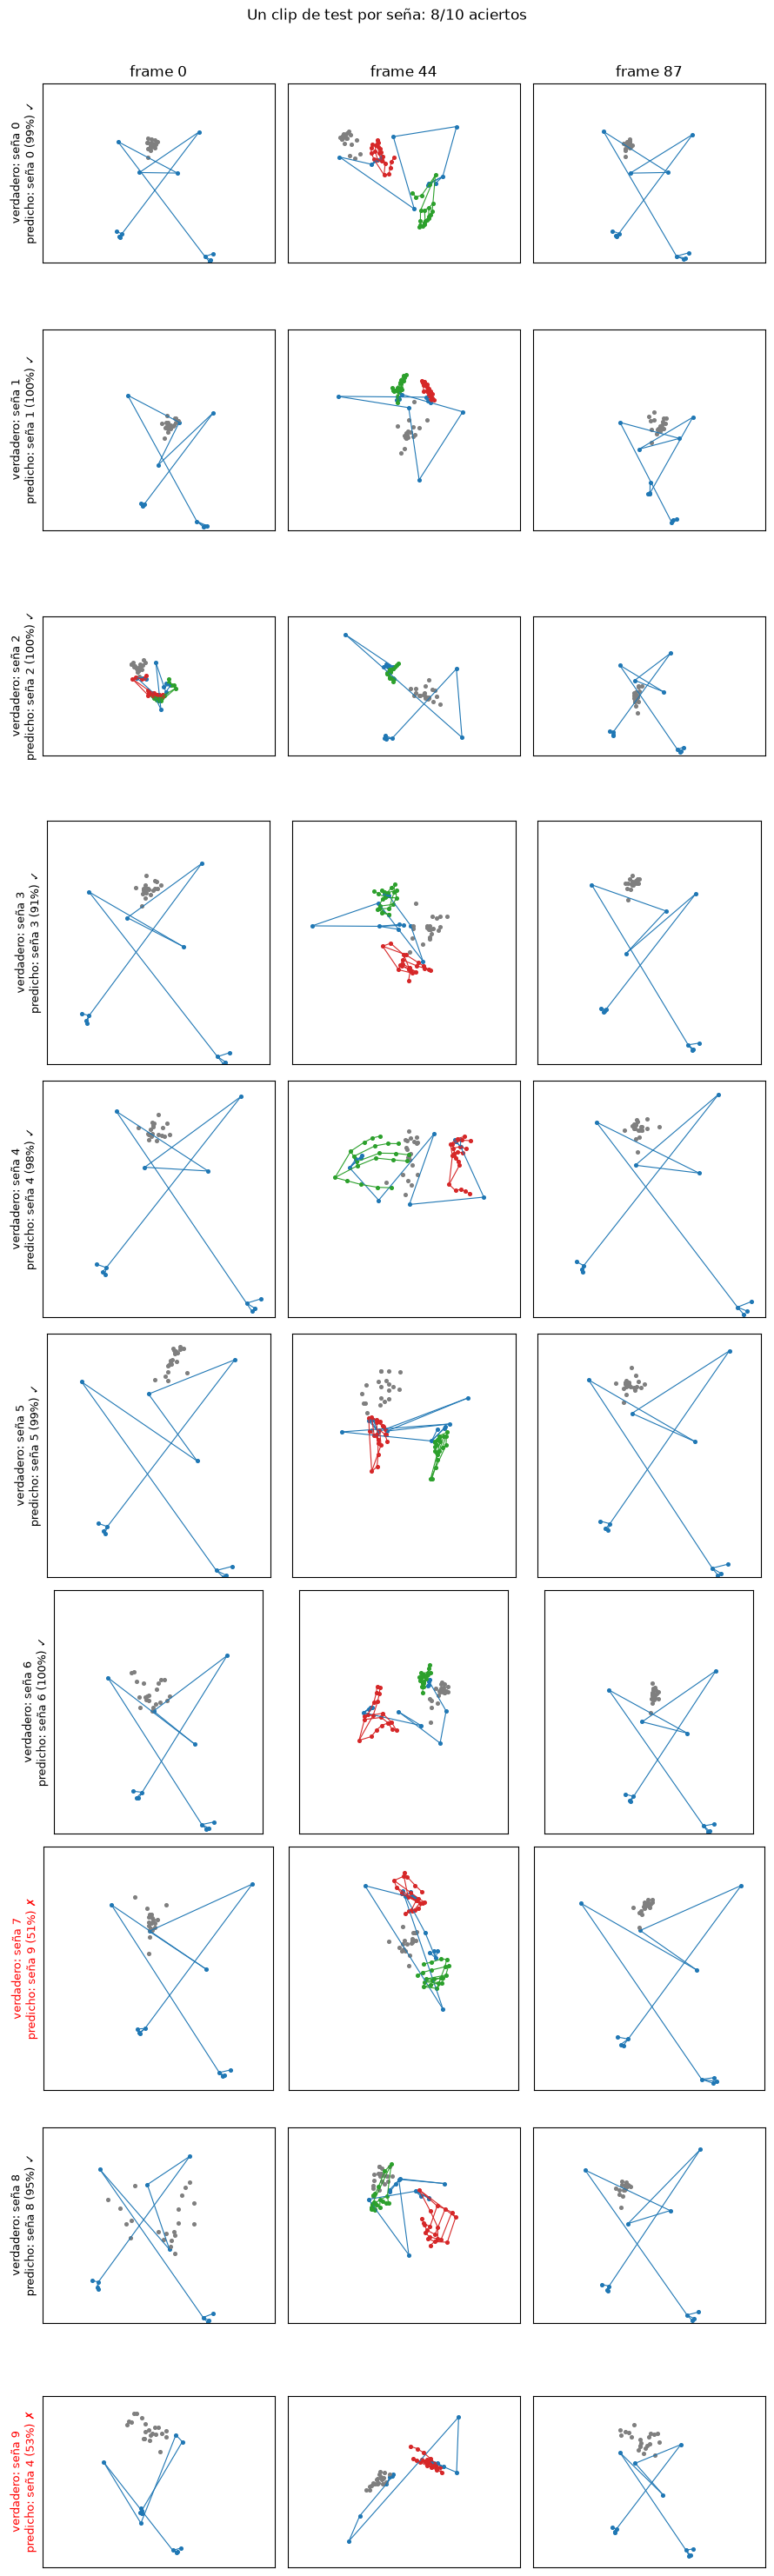

 verdadero  predicho  p(verdadero)  p(predicho)  acierto
         0         0         0.991        0.991  sí
         1         1         0.998        0.998  sí
         2         2         0.995        0.995  sí
         3         3         0.908        0.908  sí
         4         4         0.984        0.984  sí
         5         5         0.993        0.993  sí
         6         6         0.999        0.999  sí
         7         9         0.003        0.509  NO
         8         8         0.954        0.954  sí
         9         4         0.178        0.534  NO
accuracy en TODO el test del fold: 0.85


In [23]:
fold = 2
data = load_fold(fold)

# Opción 1: entrenarlo ahora (~1 min con la config por defecto)
set_seed(0)
model = SignTransformer("separated", max_len=196)
model, hist, be = train_transformer(model, data)

# Opción 2: cargar uno que guardaste con train_and_save
# model = SignTransformer("separated", max_len=196).to(DEVICE)
# model.load_state_dict(torch.load("/ruta/separated_f4_s0.pt", map_location=DEVICE))

demo_una_por_sena(model, data)                 # si tienes los nombres: class_names=["hola", ...]
print("accuracy en TODO el test del fold:", evaluate_tf(model, to_device(data["test"]))[1])

### Subconjuntos de datos 1-5-todo

In [20]:
import json
import numpy as np
import pandas as pd

SPLITS_CSV = DIR_DATASET_LOSO / "splits_loso.csv"       # ruta a tu archivo de splits
KS = [1, 5]                              # clips por seña y por firmante
SUBSET_SEED = 0                          # semilla fija: siempre los mismos clips

splits = pd.read_csv(SPLITS_CSV)
subsets = {}

for fold in range(1, 6):
    # Clips de entrenamiento de este fold, en el mismo orden que el .npz
    tr = splits[(splits.fold == fold) & (splits.split == "train")].reset_index(drop=True)

    # Comprobación: el orden del CSV coincide con el del .npz (mismas duraciones, en el mismo orden)
    L = np.load(C.DATA_DIR / f"fold{fold}" / "train_standardized.npz")["lengths"]
    assert len(L) == len(tr), f"fold {fold}: {len(L)} clips en el .npz y {len(tr)} en el CSV"
    assert (L == tr.n_frames.values).all(), f"fold {fold}: el orden del CSV no coincide con el .npz"

    rng = np.random.default_rng(SUBSET_SEED + fold)
    subsets[fold] = {k: [] for k in KS}
    for (signer, label), g in tr.groupby(["signer", "label"]):
        perm = rng.permutation(g.index.values)              # barajar los clips de esta persona y esta seña
        for k in KS:
            subsets[fold][k] += sorted(perm[:k].tolist())   # los primeros k: anidado

    # Comprobaciones: tamaño, k clips por (firmante, seña) y anidamiento
    for k in KS:
        sel = tr.loc[subsets[fold][k]]
        assert (sel.groupby(["signer", "label"]).size() == k).all()
        assert len(sel) == 4 * 10 * k
    assert set(subsets[fold][1]) <= set(subsets[fold][5])
    print(f"fold {fold}: k=1 -> {len(subsets[fold][1])} clips, k=5 -> {len(subsets[fold][5])} clips  OK")

with open("subsets_k.json", "w") as f:
    json.dump({str(fo): {str(k): v for k, v in d.items()} for fo, d in subsets.items()}, f)
print("Guardado en subsets_k.json")

fold 1: k=1 -> 40 clips, k=5 -> 200 clips  OK
fold 2: k=1 -> 40 clips, k=5 -> 200 clips  OK
fold 3: k=1 -> 40 clips, k=5 -> 200 clips  OK
fold 4: k=1 -> 40 clips, k=5 -> 200 clips  OK
fold 5: k=1 -> 40 clips, k=5 -> 200 clips  OK
Guardado en subsets_k.json


### Experimentos

In [26]:
#HIPERPARAMETROS FIJADOS
from pathlib import Path
from types import SimpleNamespace

C = SimpleNamespace(
    DATA_DIR=Path(DIR_DATASET_LOSO),  # la variable que ya usas: contiene fold1/ ... fold5/
    RESULTS_DIR=Path("results"),
    N_CLASSES=10,
    IN_DIM=237,

    # Arquitectura (fija, propia de cada modelo)
    ARCH={
        "gru":   dict(hidden=64, dropout=0.3),
        "fact":  dict(attention="separated", d_model=64, heads=4, layers=2, mlp_ratio=2,
                      dropout=0.1, patch=4, order="st", use_det_flag=False),
        "joint": dict(attention="joint",     d_model=64, heads=4, layers=2, mlp_ratio=2,
                      dropout=0.1, patch=4, use_det_flag=False),
    },

    # Entrenamiento (fijo, igual para los tres)
    TRAIN=dict(optimizer="adamw", weight_decay=0.01, batch_size=16,
               warmup_frac=0.05, grad_clip=1.0, eval_every=25),

    # Elegido en el piloto (fold 1) y congelado
    LR={"gru": 3e-4, "fact": 3e-3, "joint": 3e-3},
    MAX_STEPS=3300,        # ~150 épocas con los 340 clips de entrenamiento
    SEEDS=[0, 1, 2],
)

In [37]:
import copy, json, math, random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support



# ----------------------------------------------------------------------------- utilidades
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_model(name):
    a = C.ARCH[name]
    if name == "gru":
        return GRUClassifier(C.IN_DIM, a["hidden"], C.N_CLASSES, dropout=a["dropout"])
    return SignTransformer(n_classes=C.N_CLASSES, **a)


def load_split(fold, split, idx=None):
    d = np.load(C.DATA_DIR / f"fold{fold}" / f"{split}_standardized.npz")
    X, y, L = d["X"], d["y"], d["lengths"]
    if idx is not None:                       # subconjunto de entrenamiento (E2)
        X, y, L = X[idx], y[idx], L[idx]
    return (torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long),
            torch.tensor(L, dtype=torch.long))


def batches(X, y, L, batch_size, shuffle, gen=None):
    n = len(y)
    order = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, batch_size):
        b = order[i:i + batch_size]
        Lb = L[b]
        T = int(Lb.max())                     # padding dinámico: recorta al clip más largo del lote
        yield X[b, :T], y[b], Lb


@torch.no_grad()
def evaluate(model, data, device, batch_size=64):
    model.eval()
    X, y, L = data
    logits = []
    for xb, _, lb in batches(X, y, L, batch_size, shuffle=False):
        logits.append(model(xb.to(device), lb.to(device)).float().cpu())
    logits = torch.cat(logits)
    pred = logits.argmax(1)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y.numpy(), pred.numpy(), average="macro", zero_division=0)
    return dict(
        loss=F.cross_entropy(logits, y).item(),
        acc=(pred == y).float().mean().item(),
        precision_macro=prec, recall_macro=rec, f1_macro=f1,
        pred=pred.tolist(), true=y.tolist(),
    )


def lr_lambda(max_steps, warmup_frac):
    warm = max(1, int(warmup_frac * max_steps))
    def f(step):
        if step < warm:
            return (step + 1) / warm
        p = (step - warm) / max(1, max_steps - warm)
        return 0.5 * (1 + math.cos(math.pi * p))
    return f


# ----------------------------------------------------------------------------- sanity checks
def sanity_check(model_name, fold=1, device="cpu", steps=300):
    """Paso 0.4: pérdida inicial ~ ln(10) y capacidad de memorizar un mini-batch."""
    set_seed(0)
    model = build_model(model_name).to(device)
    X, y, L = load_split(fold, "train")
    xb, yb, lb = next(batches(X, y, L, C.TRAIN["batch_size"], shuffle=True,
                              gen=torch.Generator().manual_seed(0)))
    xb, yb, lb = xb.to(device), yb.to(device), lb.to(device)

    model.eval()
    with torch.no_grad():
        init = F.cross_entropy(model(xb, lb), yb).item()

    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
    for _ in range(steps):
        opt.zero_grad()
        loss = F.cross_entropy(model(xb, lb), yb)
        loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        final = F.cross_entropy(model(xb, lb), yb).item()
        acc = (model(xb, lb).argmax(1) == yb).float().mean().item()

    # padding: añadir frames de relleno no debe cambiar la salida
    with torch.no_grad():
        pad = torch.zeros(xb.shape[0], 8, xb.shape[2], device=device)
        diff = (model(xb, lb) - model(torch.cat([xb, pad], 1), lb)).abs().max().item()

    ok = abs(init - math.log(C.N_CLASSES)) < 0.5 and acc == 1.0 and diff < 1e-4
    print(f"[sanity] {model_name:5s} params={count_params(model):>8,}  "
          f"pérdida inicial={init:.2f} (esperado ~{math.log(C.N_CLASSES):.2f})  "
          f"tras memorizar 1 lote={final:.3f} acc={acc:.0%}  "
          f"efecto del relleno={diff:.1e}  -> {'OK' if ok else 'REVISAR'}")
    return ok


# ----------------------------------------------------------------------------- eficiencia
@torch.no_grad()
def measure_latency(model, data, device, n_warmup=10):
    """Tiempo de inferencia por clip (batch 1, cada clip con su duración real), en ms."""
    model.eval()
    X, _, L = data
    def one(i):
        x = X[i:i + 1, :int(L[i])].to(device)
        return model(x, L[i:i + 1].to(device))
    for i in range(min(n_warmup, len(L))):        # calentamiento: no se mide
        one(i)
    times = []
    for i in range(len(L)):
        if device == "cuda":
            torch.cuda.synchronize()
        t = time.perf_counter()
        one(i)
        if device == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t) * 1000)
    return float(np.mean(times)), float(np.std(times))


# ----------------------------------------------------------------------------- una corrida
def run(model_name, fold, seed, lr, max_steps, k="all", train_idx=None,
        eval_test=False, out_path=None, device=None):
    """Entrena un modelo y devuelve (y guarda) sus resultados.

    - Entrena max_steps pasos y evalúa el modelo final (la validación se registra en history).
    - El test solo se evalúa si eval_test=True (nunca en el piloto).
    - Mide eficiencia: parámetros, tiempo de entrenamiento (sin las validaciones),
      tiempo por época, memoria pico de GPU y tiempo de inferencia por clip.
    - Si out_path ya existe, no se vuelve a entrenar (reanudable).
    """
    if out_path is not None and out_path.exists():
        print(f"  ya existe, se salta: {out_path.name}")
        return json.loads(out_path.read_text())

    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)

    train = load_split(fold, "train", train_idx)
    val = load_split(fold, "val")
    steps_per_epoch = math.ceil(len(train[1]) / C.TRAIN["batch_size"])

    model = build_model(model_name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=C.TRAIN["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(max_steps, C.TRAIN["warmup_frac"]))

    history, best = [], dict(val_loss=float("inf"))
    step, eval_time = 0, 0.0
    if device == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()        # el pico se reinicia en cada corrida
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    while step < max_steps:
        model.train()
        for xb, yb, lb in batches(*train, C.TRAIN["batch_size"], shuffle=True, gen=gen):
            xb, yb, lb = xb.to(device), yb.to(device), lb.to(device)
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), C.TRAIN["grad_clip"])
            opt.step(); sched.step(); step += 1

            if step % C.TRAIN["eval_every"] == 0 or step == max_steps:
                if device == "cuda":
                    torch.cuda.synchronize()
                te = time.perf_counter()
                v = evaluate(model, val, device)
                eval_time += time.perf_counter() - te   # no cuenta como tiempo de entrenamiento
                history.append(dict(step=step, train_loss=loss.item(),
                                    val_loss=v["loss"], val_acc=v["acc"]))
                if v["loss"] < best["val_loss"]:
                    best = dict(step=step, val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1_macro"])
                model.train()
            if step >= max_steps:
                break

    if device == "cuda":
        torch.cuda.synchronize()
    total = time.perf_counter() - t0
    train_time = total - eval_time
    res = dict(
        model=model_name, fold=fold, seed=seed, lr=lr, k=k, max_steps=max_steps,
        n_train=len(train[1]), steps_per_epoch=steps_per_epoch,
        params=count_params(model), arch=C.ARCH[model_name], train_cfg=C.TRAIN,
        device=device,
        train_time_s=train_time,                                   # solo entrenamiento
        eval_time_s=eval_time,                                     # validaciones periódicas
        time_per_epoch_s=train_time / (max_steps / steps_per_epoch),
        peak_mem_gb=(torch.cuda.max_memory_allocated() / 1e9) if device == "cuda" else None,
        best=best, history=history,
    )

    if eval_test:                             # solo en E1/E2: se evalúa el modelo final (3300 pasos)
        test = load_split(fold, "test")
        t = evaluate(model, test, device)
        res["test"] = {m: t[m] for m in ("loss", "acc", "precision_macro", "recall_macro", "f1_macro")}
        res["test_pred"], res["test_true"] = t["pred"], t["true"]
        res["latency_ms_mean"], res["latency_ms_std"] = measure_latency(model, test, device)

    if out_path is not None:
        out_path.parent.mkdir(parents=True, exist_ok=True)
        out_path.write_text(json.dumps(res, indent=1))
    return res

def report(r):
    t = r["test"]
    mem = f"{r['peak_mem_gb']:.2f} GB" if r["peak_mem_gb"] is not None else "n/d"
    print(f"   TEST  acc={t['acc']:.1%}  precision={t['precision_macro']:.3f}  "
          f"recall={t['recall_macro']:.3f}  F1={t['f1_macro']:.3f}")
    print(f"   COSTO params={r['params']:,}  entrenamiento={r['train_time_s'] / 60:.1f} min  "
          f"época={r['time_per_epoch_s']:.2f} s  memoria pico={mem}  "
          f"inferencia={r['latency_ms_mean']:.1f} ms/clip")

### E1: DATOS COMPLETOS

In [38]:
# E1: 3 modelos x 5 folds x 3 semillas, todos los datos de entrenamiento
MODELS = ["gru", "fact", "joint"]        # el conjunto al final: es el más lento
OUT_E1 = C.RESULTS_DIR / "E1"

for m in MODELS:
    for fold in range(1, 6):
        for seed in C.SEEDS:
            print(f"== E1  {m}  fold {fold}  seed {seed}")
            r = run(m, fold=fold, seed=seed, lr=C.LR[m], max_steps=C.MAX_STEPS, k="all",
                    eval_test=True, out_path=OUT_E1 / f"{m}_f{fold}_s{seed}.json")
            report(r)

== E1  gru  fold 1  seed 0
   TEST  acc=46.0%  precision=0.351  recall=0.460  F1=0.375
   COSTO params=58,826  entrenamiento=0.7 min  época=0.27 s  memoria pico=0.04 GB  inferencia=1.6 ms/clip
== E1  gru  fold 1  seed 1
   TEST  acc=53.0%  precision=0.555  recall=0.530  F1=0.488
   COSTO params=58,826  entrenamiento=0.6 min  época=0.25 s  memoria pico=0.04 GB  inferencia=1.5 ms/clip
== E1  gru  fold 1  seed 2
   TEST  acc=44.0%  precision=0.442  recall=0.440  F1=0.369
   COSTO params=58,826  entrenamiento=0.7 min  época=0.26 s  memoria pico=0.04 GB  inferencia=1.6 ms/clip
== E1  gru  fold 2  seed 0
   TEST  acc=61.0%  precision=0.752  recall=0.610  F1=0.594
   COSTO params=58,826  entrenamiento=0.6 min  época=0.24 s  memoria pico=0.04 GB  inferencia=2.3 ms/clip
== E1  gru  fold 2  seed 1
   TEST  acc=69.0%  precision=0.709  recall=0.690  F1=0.642
   COSTO params=58,826  entrenamiento=0.6 min  época=0.25 s  memoria pico=0.04 GB  inferencia=2.2 ms/clip
== E1  gru  fold 2  seed 2
   TEST 

### E2: DATOS REDUCIDOS

In [ ]:
# E2: 3 modelos x 5 folds x k reducidos, 1 semilla (k = 3 solo si da tiempo)
E2_KS = [1, 5]
OUT_E2 = C.RESULTS_DIR / "E2"

for k in E2_KS:
    for m in ["gru", "fact", "joint"]:
        for fold in range(1, 6):
            print(f"== E2  k={k}  {m}  fold {fold}")
            r = run(m, fold=fold, seed=0, lr=C.LR[m], max_steps=C.MAX_STEPS, k=k,
                    train_idx=subsets[fold][k], eval_test=True,
                    out_path=OUT_E2 / f"{m}_k{k}_f{fold}_s0.json")
            report(r)

== E2  k=1  gru  fold 1


KeyboardInterrupt: 

# ---TESIS PANAMÁ---

# 8. Graph nodes

In [21]:
# Graph node layout.
#
# A GCN needs one uniform (T, V, C) tensor: V nodes, each with the same C
# features. The stored vectors are not uniform -- pose landmarks carry a fourth
# value, visibility, that face and hand landmarks do not have. Dropping it gives
# every node the same three spatial coordinates.
#
# Which landmarks exist at all is decided in section 2, so every node here is a
# landmark the model actually uses. Visibility is the one thing still stored and
# not used: it is 12 columns, and keeping it means the with/without-visibility
# ablation is a change to this slice rather than another extraction run.

N_NODES = N_POSE + N_FACE + 2 * N_HAND  # 12 + 21 + 21 + 21 = 75
N_COORDS = 3                            # x, y, z

# Where each body part sits in the node axis, for building the adjacency matrix
# and for reading results back out per part.
POSE_NODES = slice(0, N_POSE)
FACE_NODES = slice(POSE_NODES.stop, POSE_NODES.stop + N_FACE)
LEFT_HAND_NODES = slice(FACE_NODES.stop, FACE_NODES.stop + N_HAND)
RIGHT_HAND_NODES = slice(LEFT_HAND_NODES.stop, LEFT_HAND_NODES.stop + N_HAND)


def to_nodes(X):
    """(..., FEATURE_DIM) flat vectors -> (..., N_NODES, 3) node coordinates."""
    lead = X.shape[:-1]
    parts = [
        X[..., POSE].reshape(*lead, N_POSE, 4)[..., :3],  # drop visibility
        X[..., FACE].reshape(*lead, N_FACE, 3),
        X[..., LEFT_HAND].reshape(*lead, N_HAND, 3),
        X[..., RIGHT_HAND].reshape(*lead, N_HAND, 3),
    ]
    return np.concatenate(parts, axis=-2)


for split in ("train", "val", "test"):
    data = np.load(DIR_DATASET / f"{split}.npz")
    nodes = to_nodes(data["X"])
    print(f"{split:5s}: {data['X'].shape} -> {nodes.shape}")

print(f"\n{N_NODES} nodes x {N_COORDS} coords: "
      f"pose {POSE_NODES.start}-{POSE_NODES.stop - 1} (landmarks {POSE_LANDMARK_IDS[0]}-{POSE_LANDMARK_IDS[-1]}), "
      f"face {FACE_NODES.start}-{FACE_NODES.stop - 1}, "
      f"left hand {LEFT_HAND_NODES.start}-{LEFT_HAND_NODES.stop - 1}, "
      f"right hand {RIGHT_HAND_NODES.start}-{RIGHT_HAND_NODES.stop - 1}")

train: (70, 172, 237) -> (70, 172, 75, 3)
val  : (15, 172, 237) -> (15, 172, 75, 3)
test : (15, 172, 237) -> (15, 172, 75, 3)

75 nodes x 3 coords: pose 0-11 (landmarks 11-22), face 12-32, left hand 33-53, right hand 54-74


# 9. Skeleton graph

In [22]:
# Skeleton graph.
#
# The topology is a constant -- the same 75 nodes and the same edges for every
# frame of every clip -- so it is built here at runtime from explicit edge lists
# rather than loaded from disk. Keeping it as code means it cannot go stale
# against the landmark lists in section 2: change a landmark there and this cell
# either follows automatically or fails loudly.
#
# Every edge below is anatomical: bones for the body and hands, spatial
# adjacency for the face. No shortcut edges are added to shorten paths or to
# link parts that are not physically attached. Semantic or learned connections
# are a separate approach, to be tested against this one.

# Pose and hands follow the real bone structure, taken from MediaPipe's own
# connection sets so the topology matches the model that produced the points.
# Pose edges are remapped from MediaPipe landmark ids to node indices, which
# also drops any edge touching a landmark not kept in POSE_LANDMARK_IDS.
POSE_LOCAL = {mp_id: i for i, mp_id in enumerate(POSE_LANDMARK_IDS)}
POSE_EDGES = [
    (POSE_LOCAL[a], POSE_LOCAL[b])
    for a, b in mp.solutions.pose.POSE_CONNECTIONS
    if a in POSE_LOCAL and b in POSE_LOCAL
]
HAND_EDGES = sorted(mp.solutions.hands.HAND_CONNECTIONS)

# The face mesh is not a bone structure and we keep only 21 of its 468 points,
# so its edges are defined by hand, in MediaPipe face-mesh ids (the same numbers
# as FACE_LANDMARK_IDS above) and translated to node indices below.
FACE_EDGES_BY_ID = [
    # Mouth, hanging off the chin: chin -> lower lip -> corners -> upper lip.
    (152, 17),
    (17, 61), (17, 291),
    (61, 0), (291, 0),
    # Up the midline: upper lip -> nose tip -> nose bridge.
    (0, 1), (1, 6),
    # Nose bridge out to the inner corner of each eye.
    (6, 133), (6, 362),
    # Each eye as a ring: inner corner -> both eyelids -> outer corner.
    (133, 159), (133, 145), (159, 33), (145, 33),
    (362, 386), (362, 374), (386, 263), (374, 263),
    # Midline continues up: nose bridge -> forehead -> top of face.
    (6, 9), (9, 10),
    # Eyebrows hang off the forehead: forehead -> each mid-brow -> its inner end.
    (9, 105), (9, 334),
    (105, 107), (334, 336),
]

# Bridges between the four parts. Without these the graph is four disconnected
# components and no information can flow from the hands to the body or face.
# The head attaches at the chin, the lowest face point and the one that actually
# sits near the shoulders.
FACE_TO_SHOULDERS = 152          # face-mesh chin
POSE_L_SHOULDER, POSE_R_SHOULDER = 11, 12
HAND_WRIST = 0                   # hand landmark 0 is the wrist, in both hands
POSE_L_WRIST, POSE_R_WRIST = 15, 16


def build_adjacency():
    """Undirected (N_NODES, N_NODES) adjacency, with self-loops."""
    face_index = {mp_id: i for i, mp_id in enumerate(FACE_LANDMARK_IDS)}
    edges = []

    edges += [(POSE_NODES.start + a, POSE_NODES.start + b) for a, b in POSE_EDGES]
    edges += [
        (FACE_NODES.start + face_index[a], FACE_NODES.start + face_index[b])
        for a, b in FACE_EDGES_BY_ID
    ]
    for start in (LEFT_HAND_NODES.start, RIGHT_HAND_NODES.start):
        edges += [(start + a, start + b) for a, b in HAND_EDGES]

    chin = FACE_NODES.start + face_index[FACE_TO_SHOULDERS]
    edges += [
        (chin, POSE_NODES.start + POSE_LOCAL[POSE_L_SHOULDER]),
        (chin, POSE_NODES.start + POSE_LOCAL[POSE_R_SHOULDER]),
        (LEFT_HAND_NODES.start + HAND_WRIST, POSE_NODES.start + POSE_LOCAL[POSE_L_WRIST]),
        (RIGHT_HAND_NODES.start + HAND_WRIST, POSE_NODES.start + POSE_LOCAL[POSE_R_WRIST]),
    ]

    A = np.zeros((N_NODES, N_NODES), dtype=np.float32)
    for i, j in edges:
        A[i, j] = A[j, i] = 1.0
    np.fill_diagonal(A, 1.0)  # self-loops: a node keeps its own features
    return A, edges


def normalize_adjacency(A):
    """Symmetric normalization D^-1/2 A D^-1/2, the standard GCN propagation rule.

    Without it, high-degree nodes (the wrists, which join a hand to an arm)
    would dominate every message-passing step simply by having more neighbours.
    """
    degree = A.sum(axis=1)
    d_inv_sqrt = 1.0 / np.sqrt(degree)
    return A * d_inv_sqrt[:, None] * d_inv_sqrt[None, :]


A, edges = build_adjacency()
A_norm = normalize_adjacency(A)

print(f"{N_NODES} nodes, {len(edges)} edges "
      f"(pose {len(POSE_EDGES)}, face {len(FACE_EDGES_BY_ID)}, hands 2x{len(HAND_EDGES)}, bridges 4)")
print(f"adjacency {A.shape}, symmetric: {np.array_equal(A, A.T)}")

degree = A.sum(axis=1) - 1  # minus the self-loop
isolated = np.flatnonzero(degree == 0)
print(f"isolated nodes: {len(isolated)}{'' if len(isolated) == 0 else ' -> ' + str(isolated)}")
print(f"degree: min {int(degree.min())}, max {int(degree.max())}, mean {degree.mean():.2f}")

# Connectivity check: flood-fill from node 0 must reach every node, or some part
# of the body is silently cut off from the rest.
seen, frontier = {0}, [0]
while frontier:
    frontier = [j for i in frontier for j in np.flatnonzero(A[i]) if j not in seen and not seen.add(j)]
print(f"connected: {len(seen)}/{N_NODES} nodes reachable from node 0")

75 nodes, 82 edges (pose 13, face 23, hands 2x21, bridges 4)
adjacency (75, 75), symmetric: True
isolated nodes: 0
degree: min 1, max 5, mean 2.19
connected: 75/75 nodes reachable from node 0
